# MERFISH Mouse Brain Modular Clean Splat Notebook v4


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import numpy as np
import random
import torch
import torch.nn as nn
from scipy.ndimage import distance_transform_edt

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent:
    if (
        (PROJECT_ROOT / "pyproject.toml").exists()
        and (PROJECT_ROOT / "spatsplat").is_dir()
        and (PROJECT_ROOT / "paper").is_dir()
    ):
        break
    PROJECT_ROOT = PROJECT_ROOT.parent
else:
    raise RuntimeError("Could not find the spatsplat project root")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from spatsplat import AmplitudeSplatField, DataConfig, GeneProfileAutoencoder, SplatConfig, TrainingConfig, build_cell_only_targets, capture_initial_splat_state, composition_cosine_loss, compute_splat_weights, create_amplitude_splat_optimizer, evaluate_cell_readout, evaluate_count_model, evaluate_profile_autoencoder, farthest_point_sample_indices, log_total_count_loss, mae_count_loss, make_split_indices, negative_binomial_count_loss, predict_cell_log_rates, sample_numpy_grid, sample_tissue_support, summarize_activity_slices, summarize_error_slices, train_profile_autoencoder, usage_statistics
from spatsplat.baselines import CountMLP, FourierFeatureMLP, KNNCountRegressor, MeanProfileBaseline
from paper.data_loaders.merfish_mouse_brain import load_merfish_mouse_brain_dataset


In [2]:
sample_name = 'S1R1'
include_blank_probes = False

data_cfg = DataConfig(bin_size=64, mask_grid_size=128, qv_threshold=20, cell_mask_min_radius=1.0)
splat_cfg = SplatConfig(num_splats=512, latent_dim=32, hidden_dim=128, init_log_scale=-4.5, kernel_sharpness=0.5)
init_log_amplitude = 8.0
train_cfg = TrainingConfig(
    baseline_epochs=200,
    splat_epochs=200,
    baseline_batch_size=4096,
    bin_batch_size=2048,
    cell_batch_size=2048,
    off_tissue_batch_size=2048,
    bin_loss_weight=0.05,
    cell_loss_weight=1.0,
    off_tissue_weight=0.01,
    center_support_weight=0.001,
    splat_means_lr=5e-3,
    splat_log_scales_lr=1e-3,
    splat_rotation_lr=1e-3,
    splat_opacity_lr=1e-3,
    splat_latents_lr=1e-3,
    splat_log_theta_lr=1e-3,
    splat_decoder_lr=1e-3,
    splat_total_count_head_lr=1e-3,
)

notebook_seed = 1023
split_seed = notebook_seed
ae_seed = notebook_seed + 1
seed_init_seed = notebook_seed + 2
baseline_mean_seed = notebook_seed + 3
baseline_mlp_mae_seed = notebook_seed + 4
baseline_mlp_bio_seed = notebook_seed + 5
baseline_fourier_mae_seed = notebook_seed + 6
baseline_fourier_bio_seed = notebook_seed + 7
baseline_budget_knn_seed = notebook_seed + 8
random_model_seed = notebook_seed + 9
random_train_seed = notebook_seed + 10
ae_train_seed = notebook_seed + 11
ae_frozen_train_seed = notebook_seed + 12
ae_unfrozen_train_seed = notebook_seed + 13
layout_seed = notebook_seed + 14
overlap_seed = notebook_seed + 15
comparison_gene_of_interest = 'Slc17a7'


def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if hasattr(torch.backends, 'cudnn'):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(notebook_seed)
display_sig_digits = 4


def format_scalar(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if isinstance(value, (int, np.integer)):
        return int(value)
    if isinstance(value, (float, np.floating)):
        value = float(value)
        if np.isnan(value) or np.isinf(value):
            return value
        return float(f'{value:.{display_sig_digits}g}')
    return value


def format_for_display(obj):
    if isinstance(obj, dict):
        return {k: format_for_display(v) for k, v in obj.items()}
    if isinstance(obj, list):
        return [format_for_display(v) for v in obj]
    if isinstance(obj, tuple):
        return tuple(format_for_display(v) for v in obj)
    return format_scalar(obj)

FIGURE_EXPORT_DIR = PROJECT_ROOT / 'figures' / 'merfish_mouse_brain_modular_clean'
FIGURE_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
figure_export_dir = FIGURE_EXPORT_DIR


def _slugify_figure_name(name: str) -> str:
    keep = []
    for ch in name.lower():
        if ch.isalnum():
            keep.append(ch)
        elif ch in {' ', '-', '_', '|'}:
            keep.append('_')
    slug = ''.join(keep).strip('_')
    while '__' in slug:
        slug = slug.replace('__', '_')
    return slug or 'untitled_figure'


def export_figure_axes(fig, fallback_prefix: str = "figure", dpi: int = 300, canvas_px: int = 2200):
    from PIL import Image

    titled_axes = []
    for ax in fig.axes:
        title = ax.get_title().strip() if hasattr(ax, "get_title") else ""
        if title:
            titled_axes.append((ax, title))
    if not titled_axes:
        return []

    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    width, height = fig.canvas.get_width_height()
    buf = np.frombuffer(fig.canvas.buffer_rgba(), dtype=np.uint8).reshape(height, width, 4)
    all_bboxes = {ax: ax.get_tightbbox(renderer) for ax in fig.axes}
    saved_paths = []

    def _merge_with_adjacent_colorbars(main_ax, main_bbox):
        merged = main_bbox
        main_w = max(float(main_bbox.width), 1.0)
        main_h = max(float(main_bbox.height), 1.0)
        for other_ax in fig.axes:
            if other_ax is main_ax:
                continue
            other_bbox = all_bboxes.get(other_ax)
            if other_bbox is None:
                continue
            other_title = other_ax.get_title().strip() if hasattr(other_ax, "get_title") else ""
            if other_title:
                continue

            horiz_gap = min(abs(other_bbox.x1 - merged.x0), abs(other_bbox.x0 - merged.x1))
            vert_gap = min(abs(other_bbox.y1 - merged.y0), abs(other_bbox.y0 - merged.y1))
            y_overlap = max(0.0, min(merged.y1, other_bbox.y1) - max(merged.y0, other_bbox.y0))
            x_overlap = max(0.0, min(merged.x1, other_bbox.x1) - max(merged.x0, other_bbox.x0))

            is_vertical_bar = (
                other_bbox.width < 0.22 * main_w
                and y_overlap > 0.55 * min(main_h, float(other_bbox.height))
                and horiz_gap < 0.08 * main_w
                and other_bbox.x0 >= merged.x1
            )
            is_horizontal_bar = (
                other_bbox.height < 0.22 * main_h
                and x_overlap > 0.55 * min(main_w, float(other_bbox.width))
                and vert_gap < 0.08 * main_h
                and other_bbox.y1 <= merged.y0
            )
            if is_vertical_bar or is_horizontal_bar:
                merged = merged.union([merged, other_bbox])
        return merged

    for idx, (ax, title) in enumerate(titled_axes, start=1):
        base = _slugify_figure_name(f"{fallback_prefix}_{title}")
        if not base:
            base = _slugify_figure_name(f"{fallback_prefix}_{idx}")
        out_path = FIGURE_EXPORT_DIR / f"{base}.png"

        bbox = _merge_with_adjacent_colorbars(ax, all_bboxes[ax]).expanded(1.03, 1.08)
        x0 = max(0, int(np.floor(bbox.x0)))
        y0 = max(0, int(np.floor(bbox.y0)))
        x1 = min(width, int(np.ceil(bbox.x1)))
        y1 = min(height, int(np.ceil(bbox.y1)))
        if x1 <= x0 or y1 <= y0:
            continue

        crop = buf[height - y1:height - y0, x0:x1].copy()
        crop_img = Image.fromarray(crop)
        side = max(crop_img.width, crop_img.height)
        square = Image.new("RGBA", (side, side), (255, 255, 255, 255))
        offset = ((side - crop_img.width) // 2, (side - crop_img.height) // 2)
        square.paste(crop_img, offset)
        if side != canvas_px:
            square = square.resize((canvas_px, canvas_px), Image.Resampling.LANCZOS)
        square.save(out_path)
        saved_paths.append(str(out_path))
    return saved_paths

splat_cell_readout_fn = predict_cell_log_rates
splat_cell_eval_fn = evaluate_cell_readout

loaded = load_merfish_mouse_brain_dataset(sample_name=sample_name, include_blank_probes=include_blank_probes)
dataset = build_cell_only_targets(loaded, data_cfg)

device = loaded.device
trans_df = loaded.trans_df
adata = loaded.adata
gene_list = loaded.gene_list
gene_to_id = loaded.gene_to_id
num_genes = loaded.num_genes

bin_features = dataset.bin_features
bin_targets = dataset.bin_targets
cell_features = dataset.cell_features
cell_spans = dataset.cell_spans
cell_targets = dataset.cell_targets
off_tissue_points = dataset.off_tissue_points
tissue_mask_tensor = dataset.tissue_mask_tensor
mask_grid_size = dataset.mask_grid_size

dataset_name = f'merfish_mouse_brain_{sample_name}'

print(f"Device: {device}")
print(f"Dataset: {dataset_name}")
print(f"Sample: {sample_name}")
print(f"Detected transcripts: {len(trans_df):,}")
print(f"Genes: {num_genes:,}")
print(f"Cells after join: {adata.n_obs:,}")
print(f"Cells with transcript counts: {len(cell_features):,}")
print(f"Initial log amplitude: {init_log_amplitude}")
print(f"Kernel sharpness: {splat_cfg.kernel_sharpness}")


Device: cuda
Dataset: merfish_mouse_brain_S1R1
Sample: S1R1
Detected transcripts: 54,525,244
Genes: 483
Cells after join: 78,329
Cells with transcript counts: 78,329
Initial log amplitude: 8.0
Kernel sharpness: 0.5


## Tissue View

Inspect the raw spatial-unit layout before adding any modeling code.


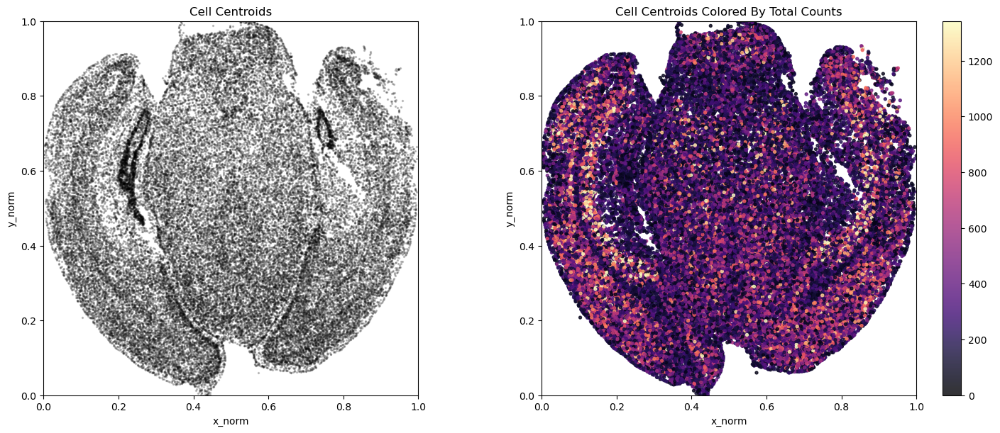

Cells shown: 50,000 / 78,329
Total count summary: mean=367.3 | median=268.0 | max=2251.0


In [3]:
cell_points_np = cell_features.detach().cpu().numpy()
cell_total_counts_np = cell_targets.sum(dim=1).detach().cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

sample_n = min(50000, len(cell_points_np))
sample_idx = np.random.default_rng(0).choice(len(cell_points_np), size=sample_n, replace=False)

axes[0].scatter(cell_points_np[sample_idx, 0], cell_points_np[sample_idx, 1], s=2, alpha=0.2, color="black")
axes[0].set_title("Cell Centroids")

vmax = np.quantile(cell_total_counts_np, 0.99) if len(cell_total_counts_np) else 1.0
sc = axes[1].scatter(
    cell_points_np[sample_idx, 0],
    cell_points_np[sample_idx, 1],
    c=cell_total_counts_np[sample_idx],
    s=8,
    cmap="magma",
    alpha=0.8,
    vmin=0.0,
    vmax=vmax,
)
axes[1].set_title("Cell Centroids Colored By Total Counts")

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.set_xlabel("x_norm")
    ax.set_ylabel("y_norm")

fig.colorbar(sc, ax=axes[1], fraction=0.046, pad=0.04)
export_figure_axes(fig, fallback_prefix="merfish_mouse_brain_cell_4_1")
plt.show()

print(f"Cells shown: {sample_n:,} / {len(cell_points_np):,}")
print(f"Total count summary: mean={format_scalar(cell_total_counts_np.mean())} | median={format_scalar(np.median(cell_total_counts_np))} | max={format_scalar(cell_total_counts_np.max())}")


## Tissue Mask Diagnostics

Check the support mask directly against the observed spatial-unit positions.


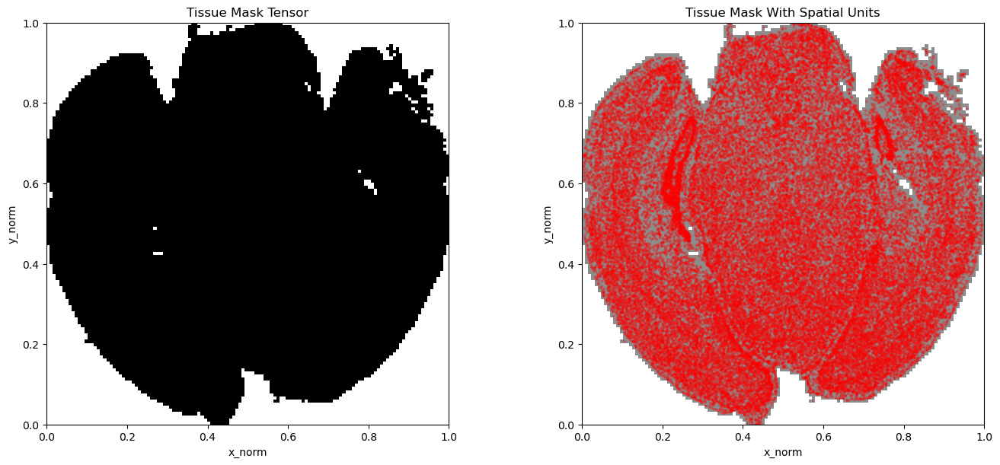

Tissue mask coverage summary
{'mask_shape': (128, 128), 'mask_mean': 0.7635, 'mask_binary_fraction_gt_0.05': 0.7635, 'sampled_spatial_units': 50000}


In [4]:
mask_np = tissue_mask_tensor.squeeze().detach().cpu().numpy()
mask_binary = mask_np > 0.05
cell_points_np = cell_features.detach().cpu().numpy()

sample_n = min(50000, len(cell_points_np))
sample_idx = np.random.default_rng(0).choice(len(cell_points_np), size=sample_n, replace=False)
sample_xy = cell_points_np[sample_idx]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)

axes[0].imshow(mask_np, origin="lower", extent=[0, 1, 0, 1], cmap="gray_r")
axes[0].set_title("Tissue Mask Tensor")

axes[1].imshow(mask_np, origin="lower", extent=[0, 1, 0, 1], cmap="gray_r", alpha=0.45)
axes[1].scatter(sample_xy[:, 0], sample_xy[:, 1], s=3, alpha=0.25, color="red")
axes[1].set_title("Tissue Mask With Spatial Units")

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.set_xlabel("x_norm")
    ax.set_ylabel("y_norm")

export_figure_axes(fig, fallback_prefix="merfish_mouse_brain_cell_6_1")
plt.show()

print("Tissue mask coverage summary")
print(format_for_display({
    "mask_shape": tuple(mask_np.shape),
    "mask_mean": float(mask_np.mean()),
    "mask_binary_fraction_gt_0.05": float(mask_binary.mean()),
    "sampled_spatial_units": int(sample_n),
}))


## Normalized Profile Autoencoder

Train an encoder/decoder on normalized gene-expression profiles so the latent space can later be used to initialize splat biology programs.


In [5]:
set_seed(ae_seed)
cell_train_idx, cell_val_idx, cell_test_idx = make_split_indices(len(cell_features), seed=split_seed, device=device)

cell_total_counts = cell_targets.sum(dim=1, keepdim=True).clamp_min(1.0)
cell_profiles = cell_targets.float() / cell_total_counts

ae_epochs = 300
ae_batch_size = 256
ae_lr = 1e-3

set_seed(ae_seed)
profile_autoencoder = GeneProfileAutoencoder(
    num_genes=num_genes,
    hidden_dim=splat_cfg.hidden_dim,
    latent_dim=splat_cfg.latent_dim,
).to(device)
print(format_for_display({
    'train_cells': int(len(cell_train_idx)),
    'val_cells': int(len(cell_val_idx)),
    'test_cells': int(len(cell_test_idx)),
    'latent_dim': int(splat_cfg.latent_dim),
    'hidden_dim': int(splat_cfg.hidden_dim),
}))


{'train_cells': 62663, 'val_cells': 7832, 'test_cells': 7834, 'latent_dim': 32, 'hidden_dim': 128}


## Autoencoder Training

Optimize the encoder/decoder only on normalized profiles. Total-count magnitude stays outside this path.


AE epoch 0 | train_loss=5.011 | val={'loss': 4.588, 'mae': 0.001976, 'cosine': 0.7047, 'n': 7832}
AE epoch 1 | train_loss=4.437 | val={'loss': 4.362, 'mae': 0.001629, 'cosine': 0.8111, 'n': 7832}
AE epoch 2 | train_loss=4.331 | val={'loss': 4.313, 'mae': 0.00156, 'cosine': 0.8331, 'n': 7832}
AE epoch 3 | train_loss=4.289 | val={'loss': 4.28, 'mae': 0.001505, 'cosine': 0.8496, 'n': 7832}
AE epoch 4 | train_loss=4.26 | val={'loss': 4.248, 'mae': 0.001447, 'cosine': 0.8646, 'n': 7832}
AE epoch 5 | train_loss=4.23 | val={'loss': 4.223, 'mae': 0.001404, 'cosine': 0.8767, 'n': 7832}
AE epoch 6 | train_loss=4.209 | val={'loss': 4.205, 'mae': 0.001371, 'cosine': 0.8834, 'n': 7832}
AE epoch 7 | train_loss=4.193 | val={'loss': 4.192, 'mae': 0.001345, 'cosine': 0.8886, 'n': 7832}
AE epoch 8 | train_loss=4.182 | val={'loss': 4.184, 'mae': 0.001331, 'cosine': 0.8913, 'n': 7832}
AE epoch 9 | train_loss=4.17 | val={'loss': 4.171, 'mae': 0.001303, 'cosine': 0.8975, 'n': 7832}
AE epoch 10 | train_loss=

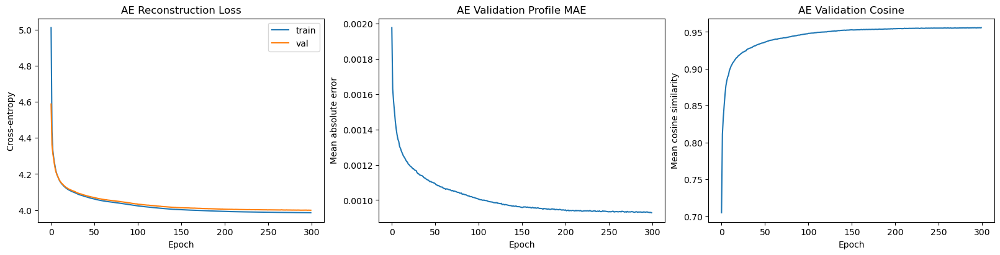

In [6]:
def log_ae_epoch(epoch, train_loss, val_metrics):
    print(f"AE epoch {epoch} | train_loss={format_scalar(train_loss)} | val={format_for_display(val_metrics)}")


ae_history = train_profile_autoencoder(
    profile_autoencoder,
    cell_profiles,
    cell_train_idx,
    cell_val_idx,
    epochs=ae_epochs,
    batch_size=ae_batch_size,
    lr=ae_lr,
    max_grad_norm=5.0,
    on_epoch_end=log_ae_epoch,
)

ae_test_metrics = evaluate_profile_autoencoder(profile_autoencoder, cell_profiles, cell_test_idx, batch_size=ae_batch_size)
print('Normalized-profile autoencoder test')
print(format_for_display(ae_test_metrics))

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
axes[0].plot(ae_history['train_loss'], label='train')
axes[0].plot(ae_history['val_loss'], label='val')
axes[0].set_title('AE Reconstruction Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-entropy')
axes[0].legend()

axes[1].plot(ae_history['val_mae'])
axes[1].set_title('AE Validation Profile MAE')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Mean absolute error')

axes[2].plot(ae_history['val_cosine'])
axes[2].set_title('AE Validation Cosine')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Mean cosine similarity')

export_figure_axes(fig, fallback_prefix="merfish_mouse_brain_cell_10_1")
plt.show()


## Autoencoder Diagnostics

Check whether reconstructed normalized profiles preserve overall composition and marker structure well enough to support latent initialization.


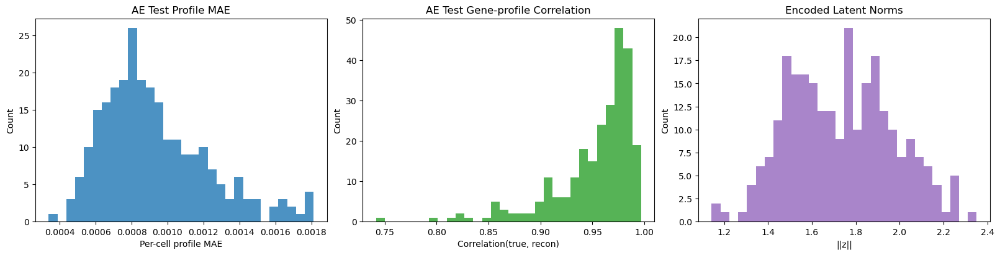

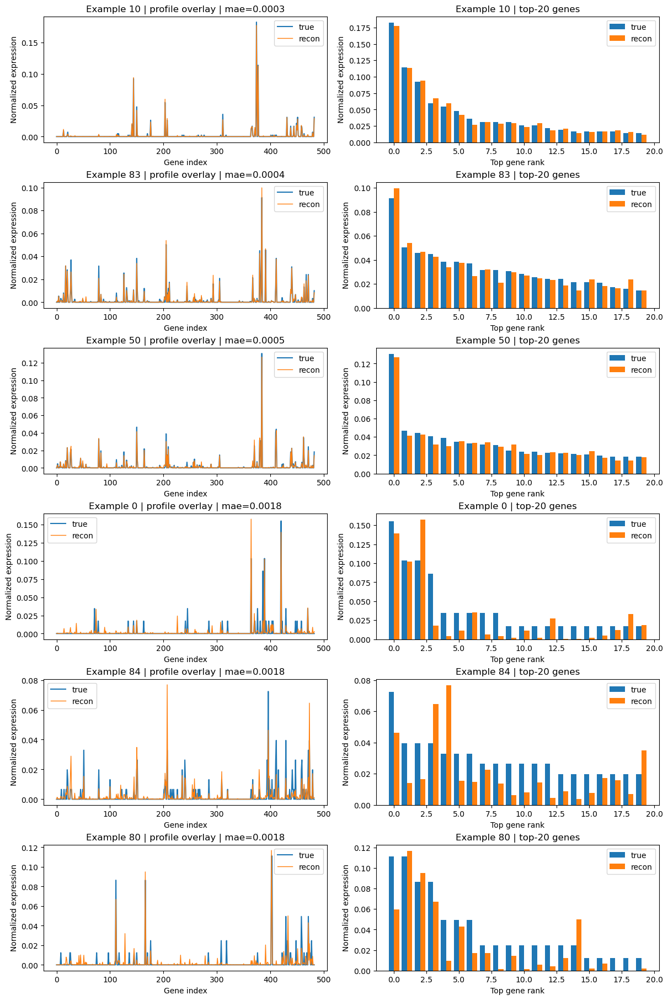

{'diag_cells': 256, 'diag_mae_mean': 0.0009271, 'diag_mae_median': 0.0008661, 'diag_corr_mean': 0.9529, 'diag_corr_median': 0.966}
Worst AE test examples by MAE
[{'local_diag_index': 80, 'original_cell_index': 63936, 'mae': 0.001813, 'corr': 0.8598}, {'local_diag_index': 84, 'original_cell_index': 48819, 'mae': 0.001807, 'corr': 0.7418}, {'local_diag_index': 0, 'original_cell_index': 57867, 'mae': 0.001795, 'corr': 0.8619}, {'local_diag_index': 173, 'original_cell_index': 36816, 'mae': 0.001769, 'corr': 0.8449}, {'local_diag_index': 199, 'original_cell_index': 16347, 'mae': 0.001723, 'corr': 0.8825}]
Worst AE test examples by correlation
[{'local_diag_index': 84, 'original_cell_index': 48819, 'mae': 0.001807, 'corr': 0.7418}, {'local_diag_index': 97, 'original_cell_index': 15490, 'mae': 0.001672, 'corr': 0.7999}, {'local_diag_index': 117, 'original_cell_index': 26326, 'mae': 0.001371, 'corr': 0.8112}, {'local_diag_index': 36, 'original_cell_index': 56771, 'mae': 0.001676, 'corr': 0.819

In [7]:
set_seed(seed_init_seed)
with torch.no_grad():
    diag_idx = cell_test_idx[:min(len(cell_test_idx), 256)]
    diag_profiles = cell_profiles[diag_idx]
    diag_latents, _, diag_recon_profiles = profile_autoencoder(diag_profiles)

diag_mae = (diag_recon_profiles - diag_profiles).abs().mean(dim=1).detach().cpu().numpy()
diag_true_np = diag_profiles.detach().cpu().numpy()
diag_recon_np = diag_recon_profiles.detach().cpu().numpy()
diag_latent_np = diag_latents.detach().cpu().numpy()
diag_corr = [np.corrcoef(t, r)[0, 1] if np.std(t) > 0 and np.std(r) > 0 else np.nan for t, r in zip(diag_true_np, diag_recon_np)]

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
axes[0].hist(diag_mae, bins=30, color='tab:blue', alpha=0.8)
axes[0].set_title('AE Test Profile MAE')
axes[0].set_xlabel('Per-cell profile MAE')
axes[0].set_ylabel('Count')

axes[1].hist([x for x in diag_corr if np.isfinite(x)], bins=30, color='tab:green', alpha=0.8)
axes[1].set_title('AE Test Gene-profile Correlation')
axes[1].set_xlabel('Correlation(true, recon)')
axes[1].set_ylabel('Count')

latent_norms = np.linalg.norm(diag_latent_np, axis=1)
axes[2].hist(latent_norms, bins=30, color='tab:purple', alpha=0.8)
axes[2].set_title('Encoded Latent Norms')
axes[2].set_xlabel('||z||')
axes[2].set_ylabel('Count')

export_figure_axes(fig, fallback_prefix="merfish_mouse_brain_cell_12_1")
plt.show()

diag_idx_np = diag_idx.detach().cpu().numpy()
diag_corr_np = np.asarray(diag_corr, dtype=np.float64)
worst_mae_order = np.argsort(diag_mae)[::-1]
finite_corr_mask = np.isfinite(diag_corr_np)
worst_corr_order = np.argsort(diag_corr_np[finite_corr_mask]) if finite_corr_mask.any() else np.array([], dtype=np.int64)
finite_corr_local_idx = np.flatnonzero(finite_corr_mask)
worst_k = min(5, len(diag_mae))
worst_mae_examples = [
    {
        'local_diag_index': int(local_idx),
        'original_cell_index': int(diag_idx_np[local_idx]),
        'mae': float(diag_mae[local_idx]),
        'corr': float(diag_corr_np[local_idx]) if np.isfinite(diag_corr_np[local_idx]) else float('nan'),
    }
    for local_idx in worst_mae_order[:worst_k]
]
worst_corr_examples = [
    {
        'local_diag_index': int(finite_corr_local_idx[pos]),
        'original_cell_index': int(diag_idx_np[finite_corr_local_idx[pos]]),
        'mae': float(diag_mae[finite_corr_local_idx[pos]]),
        'corr': float(diag_corr_np[finite_corr_local_idx[pos]]),
    }
    for pos in worst_corr_order[:worst_k]
]

example_idx = np.argsort(diag_mae)[:3].tolist() + np.argsort(diag_mae)[-3:].tolist()
example_idx = list(dict.fromkeys(example_idx))
fig, axes = plt.subplots(len(example_idx), 2, figsize=(12, 3 * len(example_idx)), constrained_layout=True)
axes = np.atleast_2d(axes)
for row, local_idx in enumerate(example_idx):
    axes[row, 0].plot(diag_true_np[local_idx], label='true', linewidth=1.5)
    axes[row, 0].plot(diag_recon_np[local_idx], label='recon', linewidth=1.0)
    axes[row, 0].set_title(f'Example {local_idx} | profile overlay | mae={diag_mae[local_idx]:.4f}')
    axes[row, 0].set_xlabel('Gene index')
    axes[row, 0].set_ylabel('Normalized expression')
    axes[row, 0].legend()

    gene_order = np.argsort(diag_true_np[local_idx])[::-1][:20]
    x = np.arange(len(gene_order))
    axes[row, 1].bar(x - 0.2, diag_true_np[local_idx, gene_order], width=0.4, label='true')
    axes[row, 1].bar(x + 0.2, diag_recon_np[local_idx, gene_order], width=0.4, label='recon')
    axes[row, 1].set_title(f'Example {local_idx} | top-20 genes')
    axes[row, 1].set_xlabel('Top gene rank')
    axes[row, 1].set_ylabel('Normalized expression')
    axes[row, 1].legend()

export_figure_axes(fig, fallback_prefix="merfish_mouse_brain_cell_12_2")
plt.show()

print(format_for_display({
    'diag_cells': int(len(diag_idx)),
    'diag_mae_mean': float(np.mean(diag_mae)),
    'diag_mae_median': float(np.median(diag_mae)),
    'diag_corr_mean': float(np.nanmean(diag_corr)),
    'diag_corr_median': float(np.nanmedian(diag_corr)),
}))
print('Worst AE test examples by MAE')
print(format_for_display(worst_mae_examples))
print('Worst AE test examples by correlation')
print(format_for_display(worst_corr_examples))


## Encoder-Initialized Splats

Use the trained encoder to initialize splat latents from local neighborhoods around initial splat centers.


In [8]:
init_neighbor_k = 16

with torch.no_grad():
    seed_idx = farthest_point_sample_indices(cell_features, splat_cfg.num_splats)
    seed_xy = cell_features[seed_idx]
    pairwise_dist = torch.cdist(seed_xy, cell_features)
    neighbor_k = min(init_neighbor_k, cell_features.shape[0])
    neighbor_dist, neighbor_idx = torch.topk(pairwise_dist, k=neighbor_k, largest=False, dim=1)

    neighbor_profiles = cell_profiles[neighbor_idx]
    neighbor_totals = cell_total_counts[neighbor_idx]
    avg_profiles = neighbor_profiles.mean(dim=1)
    avg_profiles = avg_profiles / avg_profiles.sum(dim=1, keepdim=True).clamp_min(1e-8)
    avg_totals = neighbor_totals.mean(dim=1)
    encoded_seed_latents = profile_autoencoder.encoder(avg_profiles)

def initialize_ae_seeded_splat_model(model):
    with torch.no_grad():
        model.means.copy_(seed_xy)
        model.latents.copy_(encoded_seed_latents)
        model.log_amplitudes.copy_(avg_totals.clamp_min(1.0).log())
        model.log_scales.fill_(splat_cfg.init_log_scale)
        model.rotation.zero_()
        model.opacity_logits.zero_()
        model.decoder.load_state_dict(profile_autoencoder.decoder.state_dict())
    return model

encoder_initialized_splat_model = initialize_ae_seeded_splat_model(
    AmplitudeSplatField(
        num_splats=splat_cfg.num_splats,
        latent_dim=splat_cfg.latent_dim,
        hidden_dim=splat_cfg.hidden_dim,
        num_genes=num_genes,
        init_log_scale=splat_cfg.init_log_scale,
        kernel_sharpness=splat_cfg.kernel_sharpness,
        init_log_amplitude=init_log_amplitude,
    ).to(device)
)

print(format_for_display({
    'num_splats': int(splat_cfg.num_splats),
    'neighbor_k': int(neighbor_k),
    'seed_profile_shape': tuple(avg_profiles.shape),
    'seed_latent_shape': tuple(encoded_seed_latents.shape),
    'mean_neighbor_total_count': float(avg_totals.mean().item()),
    'median_neighbor_total_count': float(avg_totals.median().item()),
}))


{'num_splats': 512, 'neighbor_k': 16, 'seed_profile_shape': (512, 483), 'seed_latent_shape': (512, 32), 'mean_neighbor_total_count': 348.6, 'median_neighbor_total_count': 329.9}


## Encoder Initialization Diagnostics

Inspect the seed locations and compare neighborhood-averaged profiles against the decoder output from the initialized latents.


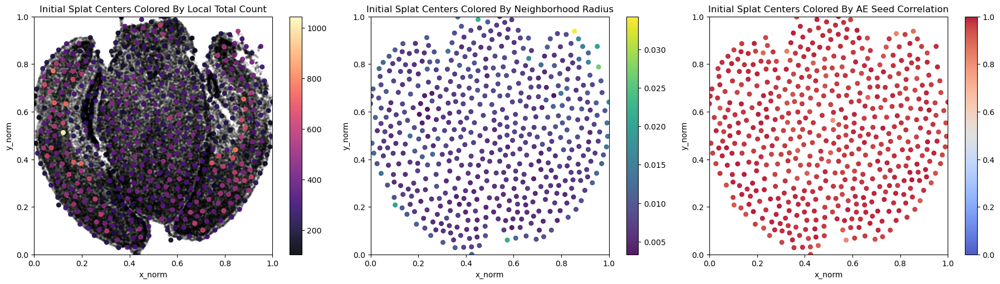

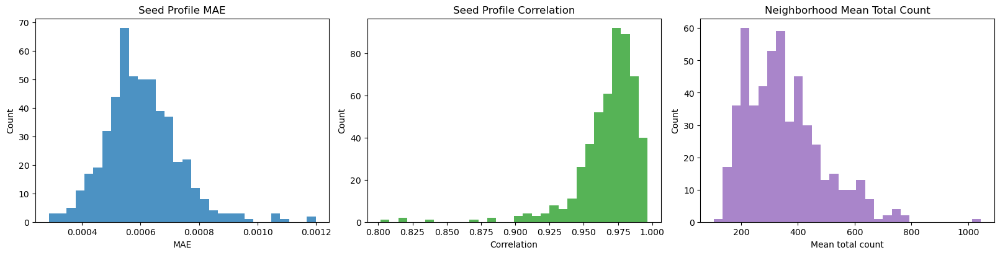

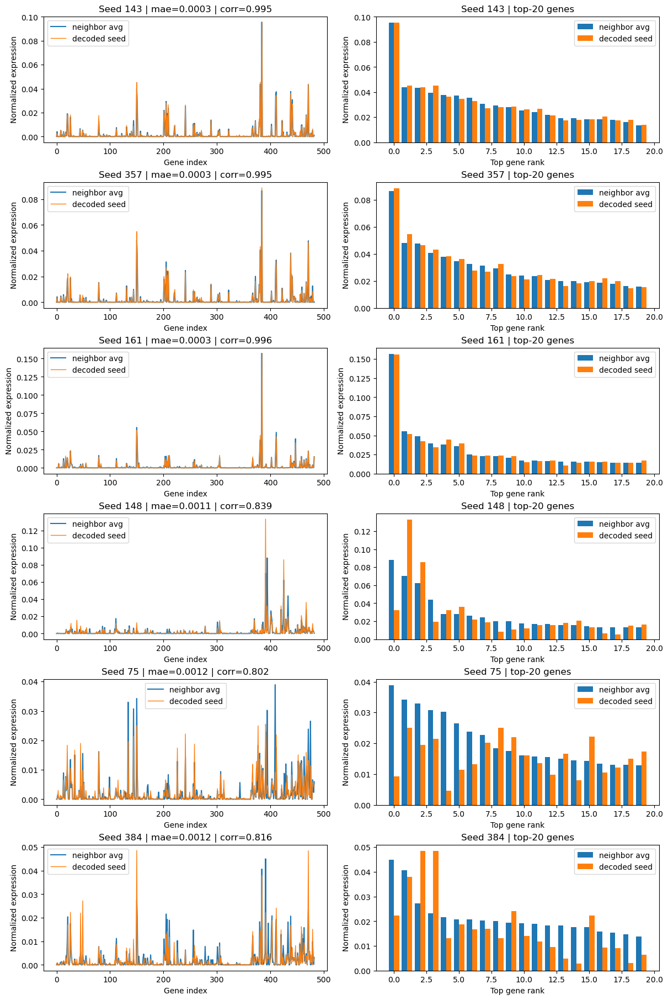

{'seed_mae_mean': 0.0006041, 'seed_mae_median': 0.0005919, 'seed_corr_mean': 0.9681, 'seed_corr_median': 0.9734, 'neighbor_radius_mean': 0.007728, 'neighbor_radius_median': 0.007055}


In [9]:
with torch.no_grad():
    seed_gene_logits, _ = encoder_initialized_splat_model.decoder(encoded_seed_latents)
    decoded_seed_profiles = torch.softmax(seed_gene_logits, dim=1)

seed_xy_np = seed_xy.detach().cpu().numpy()
avg_profiles_np = avg_profiles.detach().cpu().numpy()
decoded_seed_profiles_np = decoded_seed_profiles.detach().cpu().numpy()
avg_totals_np = avg_totals.squeeze(-1).detach().cpu().numpy()
neighbor_radius_np = neighbor_dist[:, -1].detach().cpu().numpy()
seed_mae = np.mean(np.abs(decoded_seed_profiles_np - avg_profiles_np), axis=1)
seed_corr = np.array([
    np.corrcoef(t, r)[0, 1] if np.std(t) > 0 and np.std(r) > 0 else np.nan
    for t, r in zip(avg_profiles_np, decoded_seed_profiles_np)
], dtype=np.float64)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
axes[0].scatter(cell_points_np[:, 0], cell_points_np[:, 1], s=5, alpha=0.12, color='black')
sc0 = axes[0].scatter(seed_xy_np[:, 0], seed_xy_np[:, 1], c=avg_totals_np, s=30, cmap='magma', alpha=0.9)
axes[0].set_title('Initial Splat Centers Colored By Local Total Count')
fig.colorbar(sc0, ax=axes[0], fraction=0.046, pad=0.04)

sc1 = axes[1].scatter(seed_xy_np[:, 0], seed_xy_np[:, 1], c=neighbor_radius_np, s=30, cmap='viridis', alpha=0.9)
axes[1].set_title('Initial Splat Centers Colored By Neighborhood Radius')
fig.colorbar(sc1, ax=axes[1], fraction=0.046, pad=0.04)

sc2 = axes[2].scatter(seed_xy_np[:, 0], seed_xy_np[:, 1], c=seed_corr, s=30, cmap='coolwarm', alpha=0.9, vmin=0.0, vmax=1.0)
axes[2].set_title('Initial Splat Centers Colored By AE Seed Correlation')
fig.colorbar(sc2, ax=axes[2], fraction=0.046, pad=0.04)

for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal')
    ax.set_xlabel('x_norm')
    ax.set_ylabel('y_norm')

export_figure_axes(fig, fallback_prefix="merfish_mouse_brain_cell_16_1")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
axes[0].hist(seed_mae, bins=30, color='tab:blue', alpha=0.8)
axes[0].set_title('Seed Profile MAE')
axes[0].set_xlabel('MAE')
axes[0].set_ylabel('Count')

axes[1].hist(seed_corr[np.isfinite(seed_corr)], bins=30, color='tab:green', alpha=0.8)
axes[1].set_title('Seed Profile Correlation')
axes[1].set_xlabel('Correlation')
axes[1].set_ylabel('Count')

axes[2].hist(avg_totals_np, bins=30, color='tab:purple', alpha=0.8)
axes[2].set_title('Neighborhood Mean Total Count')
axes[2].set_xlabel('Mean total count')
axes[2].set_ylabel('Count')

export_figure_axes(fig, fallback_prefix="merfish_mouse_brain_cell_16_2")
plt.show()

best_seed_idx = np.argsort(seed_mae)[:3].tolist()
worst_seed_idx = np.argsort(seed_mae)[-3:].tolist()
example_seed_idx = list(dict.fromkeys(best_seed_idx + worst_seed_idx))
fig, axes = plt.subplots(len(example_seed_idx), 2, figsize=(12, 3 * len(example_seed_idx)), constrained_layout=True)
axes = np.atleast_2d(axes)
for row, local_idx in enumerate(example_seed_idx):
    axes[row, 0].plot(avg_profiles_np[local_idx], label='neighbor avg', linewidth=1.5)
    axes[row, 0].plot(decoded_seed_profiles_np[local_idx], label='decoded seed', linewidth=1.0)
    axes[row, 0].set_title(f'Seed {local_idx} | mae={seed_mae[local_idx]:.4f} | corr={seed_corr[local_idx]:.3f}')
    axes[row, 0].set_xlabel('Gene index')
    axes[row, 0].set_ylabel('Normalized expression')
    axes[row, 0].legend()

    gene_order = np.argsort(avg_profiles_np[local_idx])[::-1][:20]
    x = np.arange(len(gene_order))
    axes[row, 1].bar(x - 0.2, avg_profiles_np[local_idx, gene_order], width=0.4, label='neighbor avg')
    axes[row, 1].bar(x + 0.2, decoded_seed_profiles_np[local_idx, gene_order], width=0.4, label='decoded seed')
    axes[row, 1].set_title(f'Seed {local_idx} | top-20 genes')
    axes[row, 1].set_xlabel('Top gene rank')
    axes[row, 1].set_ylabel('Normalized expression')
    axes[row, 1].legend()

export_figure_axes(fig, fallback_prefix="merfish_mouse_brain_cell_16_3")
plt.show()

print(format_for_display({
    'seed_mae_mean': float(np.mean(seed_mae)),
    'seed_mae_median': float(np.median(seed_mae)),
    'seed_corr_mean': float(np.nanmean(seed_corr)),
    'seed_corr_median': float(np.nanmedian(seed_corr)),
    'neighbor_radius_mean': float(np.mean(neighbor_radius_np)),
    'neighbor_radius_median': float(np.median(neighbor_radius_np)),
}))


## Baselines

Run the same baseline models used in the older notebook on the canonical train/val/test split before coarse splat training.


In [10]:
reconstruction_loss_fn = mae_count_loss
composition_loss_weight = 1.0
total_count_loss_weight = 0.1
mae_refine_weight = 1.0
mae_refine_fraction = 0.25

train_cell_features = cell_features[cell_train_idx]
train_cell_targets = cell_targets[cell_train_idx]
baseline_mae_refine_start_epoch = max(0, int(round((1.0 - mae_refine_fraction) * train_cfg.baseline_epochs)))

def train_mae_baseline(model, optimizer):
    for epoch in range(train_cfg.baseline_epochs):
        model.train()
        perm = cell_train_idx[torch.randperm(len(cell_train_idx), device=device)]
        for start in range(0, len(perm), train_cfg.baseline_batch_size):
            idx = perm[start:start + train_cfg.baseline_batch_size]
            loss = reconstruction_loss_fn(model(cell_features[idx]), cell_targets[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

def train_bio_objective_baseline(model, optimizer):
    for epoch in range(train_cfg.baseline_epochs):
        model.train()
        mae_refine_active = epoch >= baseline_mae_refine_start_epoch
        perm = cell_train_idx[torch.randperm(len(cell_train_idx), device=device)]
        for start in range(0, len(perm), train_cfg.baseline_batch_size):
            idx = perm[start:start + train_cfg.baseline_batch_size]
            pred_log_rate = model(cell_features[idx])
            pred_counts = torch.exp(pred_log_rate)
            cell_loss = mae_count_loss(pred_log_rate, cell_targets[idx]) if mae_refine_active else pred_log_rate.new_tensor(0.0)
            composition_loss = composition_cosine_loss(pred_counts, cell_targets[idx])
            total_count_loss = log_total_count_loss(pred_log_rate, cell_targets[idx])
            loss = (
                mae_refine_weight * cell_loss
                + composition_loss_weight * composition_loss
                + total_count_loss_weight * total_count_loss
            )
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

set_seed(baseline_mean_seed)
mean_cell_model = MeanProfileBaseline(train_cell_targets).to(device)
mean_cell_val = evaluate_count_model(mean_cell_model, cell_features, cell_targets, cell_val_idx, loss_fn=reconstruction_loss_fn)
mean_cell_test = evaluate_count_model(mean_cell_model, cell_features, cell_targets, cell_test_idx, loss_fn=reconstruction_loss_fn)
print('Mean baseline')
print(format_for_display(mean_cell_val))
print(format_for_display(mean_cell_test))

set_seed(baseline_mlp_mae_seed)
cell_mlp_mae = CountMLP(input_dim=2, hidden_dim=128, output_dim=num_genes).to(device)
cell_mlp_mae_opt = torch.optim.Adam(cell_mlp_mae.parameters(), lr=1e-3)
train_mae_baseline(cell_mlp_mae, cell_mlp_mae_opt)
cell_mlp_mae_val = evaluate_count_model(cell_mlp_mae, cell_features, cell_targets, cell_val_idx, loss_fn=reconstruction_loss_fn)
cell_mlp_mae_test = evaluate_count_model(cell_mlp_mae, cell_features, cell_targets, cell_test_idx, loss_fn=reconstruction_loss_fn)
print('MLP-MAE')
print(format_for_display(cell_mlp_mae_val))
print(format_for_display(cell_mlp_mae_test))

set_seed(baseline_mlp_bio_seed)
cell_mlp = CountMLP(input_dim=2, hidden_dim=128, output_dim=num_genes).to(device)
cell_mlp_opt = torch.optim.Adam(cell_mlp.parameters(), lr=1e-3)
train_bio_objective_baseline(cell_mlp, cell_mlp_opt)
cell_mlp_val = evaluate_count_model(cell_mlp, cell_features, cell_targets, cell_val_idx, loss_fn=reconstruction_loss_fn)
cell_mlp_test = evaluate_count_model(cell_mlp, cell_features, cell_targets, cell_test_idx, loss_fn=reconstruction_loss_fn)
print('MLP (Bio Objective)')
print(format_for_display(cell_mlp_val))
print(format_for_display(cell_mlp_test))

set_seed(baseline_fourier_mae_seed)
cell_fourier_mlp_mae = FourierFeatureMLP(input_dim=2, hidden_dim=128, output_dim=num_genes, num_frequencies=32, sigma=10.0).to(device)
cell_fourier_mlp_mae_opt = torch.optim.Adam(cell_fourier_mlp_mae.parameters(), lr=1e-3)
train_mae_baseline(cell_fourier_mlp_mae, cell_fourier_mlp_mae_opt)
cell_fourier_mlp_mae_val = evaluate_count_model(cell_fourier_mlp_mae, cell_features, cell_targets, cell_val_idx, loss_fn=reconstruction_loss_fn)
cell_fourier_mlp_mae_test = evaluate_count_model(cell_fourier_mlp_mae, cell_features, cell_targets, cell_test_idx, loss_fn=reconstruction_loss_fn)
print('Fourier MLP-MAE')
print(format_for_display(cell_fourier_mlp_mae_val))
print(format_for_display(cell_fourier_mlp_mae_test))

set_seed(baseline_fourier_bio_seed)
cell_fourier_mlp = FourierFeatureMLP(input_dim=2, hidden_dim=128, output_dim=num_genes, num_frequencies=32, sigma=10.0).to(device)
cell_fourier_opt = torch.optim.Adam(cell_fourier_mlp.parameters(), lr=1e-3)
train_bio_objective_baseline(cell_fourier_mlp, cell_fourier_opt)
cell_fourier_val = evaluate_count_model(cell_fourier_mlp, cell_features, cell_targets, cell_val_idx, loss_fn=reconstruction_loss_fn)
cell_fourier_test = evaluate_count_model(cell_fourier_mlp, cell_features, cell_targets, cell_test_idx, loss_fn=reconstruction_loss_fn)
print('Fourier MLP (Bio Objective)')
print(format_for_display(cell_fourier_val))
print(format_for_display(cell_fourier_test))

cell_knn = KNNCountRegressor(train_cell_features, train_cell_targets, k=64).to(device)
cell_knn_val = evaluate_count_model(cell_knn, cell_features, cell_targets, cell_val_idx, batch_size=1024, loss_fn=reconstruction_loss_fn)
cell_knn_test = evaluate_count_model(cell_knn, cell_features, cell_targets, cell_test_idx, batch_size=1024, loss_fn=reconstruction_loss_fn)
print('KNN')
print(format_for_display(cell_knn_val))
print(format_for_display(cell_knn_test))

set_seed(baseline_budget_knn_seed)
budget_knn_budget = min(splat_cfg.num_splats, len(cell_train_idx))
budget_knn_candidate_limit = None
if len(cell_train_idx) > 100000:
    budget_knn_candidate_limit = min(len(cell_train_idx), max(4 * budget_knn_budget, 50000))
budget_knn_local_idx = farthest_point_sample_indices(
    train_cell_features,
    budget_knn_budget,
    candidate_limit=budget_knn_candidate_limit,
    random_state=baseline_budget_knn_seed,
)
cell_budget_knn = KNNCountRegressor(
    train_cell_features[budget_knn_local_idx],
    train_cell_targets[budget_knn_local_idx],
    k=64,
).to(device)
cell_budget_knn_val = evaluate_count_model(cell_budget_knn, cell_features, cell_targets, cell_val_idx, batch_size=1024, loss_fn=reconstruction_loss_fn)
cell_budget_knn_test = evaluate_count_model(cell_budget_knn, cell_features, cell_targets, cell_test_idx, batch_size=1024, loss_fn=reconstruction_loss_fn)
print('Budget-matched KNN')
print(format_for_display({
    'prototype_cells': int(len(budget_knn_local_idx)),
    'candidate_pool': int(budget_knn_candidate_limit or len(cell_train_idx)),
}))
print(format_for_display(cell_budget_knn_val))
print(format_for_display(cell_budget_knn_test))

baseline_summary = {
    'Mean baseline': {'val': mean_cell_val, 'test': mean_cell_test},
    'MLP-MAE': {'val': cell_mlp_mae_val, 'test': cell_mlp_mae_test},
    'MLP (Bio Objective)': {'val': cell_mlp_val, 'test': cell_mlp_test},
    'Fourier MLP-MAE': {'val': cell_fourier_mlp_mae_val, 'test': cell_fourier_mlp_mae_test},
    'Fourier MLP (Bio Objective)': {'val': cell_fourier_val, 'test': cell_fourier_test},
    'KNN': {'val': cell_knn_val, 'test': cell_knn_test},
    'Budget-matched KNN': {'val': cell_budget_knn_val, 'test': cell_budget_knn_test},
}
print('Baseline summary')
print(format_for_display(baseline_summary))

for model_name in ['mean_cell_model', 'cell_mlp_mae', 'cell_mlp', 'cell_fourier_mlp_mae', 'cell_fourier_mlp']:
    globals()[model_name] = globals()[model_name].cpu()
del cell_mlp_mae_opt
del cell_mlp_opt
del cell_fourier_mlp_mae_opt
del cell_fourier_opt
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Mean baseline
{'loss': 0.9455, 'mae': 0.9455, 'n': 7832}
{'loss': 0.9497, 'mae': 0.9497, 'n': 7834}
MLP-MAE
{'loss': 0.7123, 'mae': 0.7123, 'n': 7832}
{'loss': 0.7156, 'mae': 0.7156, 'n': 7834}
MLP (Bio Objective)
{'loss': 0.7303, 'mae': 0.7303, 'n': 7832}
{'loss': 0.7341, 'mae': 0.7341, 'n': 7834}
Fourier MLP-MAE
{'loss': 0.6978, 'mae': 0.6978, 'n': 7832}
{'loss': 0.6963, 'mae': 0.6963, 'n': 7834}
Fourier MLP (Bio Objective)
{'loss': 0.6924, 'mae': 0.6924, 'n': 7832}
{'loss': 0.6948, 'mae': 0.6948, 'n': 7834}
KNN
{'loss': 0.8159, 'mae': 0.8159, 'n': 7832}
{'loss': 0.8209, 'mae': 0.8209, 'n': 7834}
Budget-matched KNN
{'prototype_cells': 512, 'candidate_pool': 62663}
{'loss': 0.8929, 'mae': 0.8929, 'n': 7832}
{'loss': 0.8982, 'mae': 0.8982, 'n': 7834}
Baseline summary
{'Mean baseline': {'val': {'loss': 0.9455, 'mae': 0.9455, 'n': 7832}, 'test': {'loss': 0.9497, 'mae': 0.9497, 'n': 7834}}, 'MLP-MAE': {'val': {'loss': 0.7123, 'mae': 0.7123, 'n': 7832}, 'test': {'loss': 0.7156, 'mae': 0.71

## Coarse Splat Training Setup

Train the coarse splat field with the same objective and schedule as the clean notebook, but use a reduced 5-point cell readout for splat training and evaluation: the cell center plus four axial offsets. This tests whether a milder within-cell averaging scheme preserves more count calibration than the full readout without collapsing into the center-only regime.


In [11]:
reconstruction_loss_fn = mae_count_loss
composition_loss_weight = 1.0
total_count_loss_weight = 0.2
mae_refine_weight = 1.0
mae_refine_fraction = 0.25
freeze_geometry_during_mae_refine = True
coarse_log_every = 10

def build_random_splat_model():
    return AmplitudeSplatField(
        num_splats=splat_cfg.num_splats,
        latent_dim=splat_cfg.latent_dim,
        hidden_dim=splat_cfg.hidden_dim,
        num_genes=num_genes,
        init_log_scale=splat_cfg.init_log_scale,
        kernel_sharpness=splat_cfg.kernel_sharpness,
        init_log_amplitude=init_log_amplitude,
    ).to(device)

def clone_splat_model(model):
    cloned = type(model)(
        num_splats=model.num_splats,
        latent_dim=model.latent_dim,
        hidden_dim=model.hidden_dim,
        num_genes=model.num_genes,
        init_log_scale=model.init_log_scale,
        kernel_sharpness=model.kernel_sharpness,
        init_log_amplitude=float(model.log_amplitudes.detach().mean().item()),
    ).to(model.means.device)
    cloned.load_state_dict({k: v.detach().clone() for k, v in model.state_dict().items()})
    cloned.eval()
    return cloned

def train_coarse_splat_model(initial_model, label: str, seed: int, freeze_decoder: bool = False, freeze_geometry_during_mae: bool = True, num_epochs = None):
    set_seed(seed)
    splat_model = clone_splat_model(initial_model)
    if freeze_decoder:
        for param in splat_model.decoder.parameters():
            param.requires_grad_(False)
    initial_state = capture_initial_splat_state(splat_model)
    splat_opt = create_amplitude_splat_optimizer(
        splat_model,
        means_lr=train_cfg.splat_means_lr,
        log_scales_lr=train_cfg.splat_log_scales_lr,
        rotation_lr=train_cfg.splat_rotation_lr,
        opacity_lr=train_cfg.splat_opacity_lr,
        latents_lr=train_cfg.splat_latents_lr,
        log_theta_lr=train_cfg.splat_log_theta_lr,
        decoder_lr=train_cfg.splat_decoder_lr,
        amplitude_lr=train_cfg.splat_total_count_head_lr,
    )
    train_epochs = int(train_cfg.splat_epochs if num_epochs is None else num_epochs)
    coarse_mae_refine_start_epoch = max(0, int(round((1.0 - mae_refine_fraction) * train_epochs)))
    history = {
        'train_joint_loss': [],
        'train_composition_loss': [],
        'train_total_count_loss': [],
        'train_cell_loss': [],
        'val_loss': [],
        'val_mae': [],
        'val_phase': [],
    }
    print(f"{label} | coarse loss weights: composition={format_scalar(composition_loss_weight)}, total={format_scalar(total_count_loss_weight)}, mae_refine={format_scalar(mae_refine_weight)}, off_tissue={format_scalar(train_cfg.off_tissue_weight)}, center_support={format_scalar(train_cfg.center_support_weight)}, freeze_decoder={freeze_decoder}, freeze_geometry_during_mae={freeze_geometry_during_mae}")

    for epoch in range(train_epochs):
        splat_model.train()
        mae_refine_active = epoch >= coarse_mae_refine_start_epoch
        geometry_lr_scale = 0.0 if (mae_refine_active and freeze_geometry_during_mae) else 1.0
        splat_opt.param_groups[0]['lr'] = train_cfg.splat_means_lr * geometry_lr_scale
        splat_opt.param_groups[1]['lr'] = train_cfg.splat_log_scales_lr * geometry_lr_scale
        splat_opt.param_groups[2]['lr'] = train_cfg.splat_rotation_lr * geometry_lr_scale
        splat_opt.param_groups[3]['lr'] = train_cfg.splat_opacity_lr * geometry_lr_scale
        splat_opt.param_groups[4]['lr'] = train_cfg.splat_latents_lr
        splat_opt.param_groups[5]['lr'] = train_cfg.splat_log_theta_lr
        splat_opt.param_groups[6]['lr'] = 0.0 if freeze_decoder else train_cfg.splat_decoder_lr
        splat_opt.param_groups[7]['lr'] = train_cfg.splat_total_count_head_lr
        cell_perm = cell_train_idx[torch.randperm(len(cell_train_idx), device=device)]
        off_perm = torch.randperm(len(off_tissue_points), device=device)
        batch_size = min(train_cfg.cell_batch_size, 1024)
        off_batch_size = min(train_cfg.off_tissue_batch_size, 1024)
        num_steps = max(1, (len(cell_perm) + batch_size - 1) // batch_size)
        running = {
            'joint_loss': 0.0,
            'cell_loss': 0.0,
            'composition_loss': 0.0,
            'total_count_loss': 0.0,
            'off_tissue_loss': 0.0,
            'center_support_loss': 0.0,
        }

        for step in range(num_steps):
            cell_start = (step * batch_size) % len(cell_perm)
            off_start = (step * off_batch_size) % len(off_perm)
            cell_idx = cell_perm[cell_start:cell_start + batch_size]
            off_idx = off_perm[off_start:off_start + off_batch_size]
            if len(cell_idx) == 0:
                cell_idx = cell_perm[:batch_size]
            if len(off_idx) == 0:
                off_idx = off_perm[:off_batch_size]

            pred_cell_log_rate = splat_cell_readout_fn(
                splat_model,
                cell_features[cell_idx],
                cell_spans[cell_idx],
                batch_size=batch_size,
            )
            off_tissue_intensity = splat_model.total_intensity(off_tissue_points[off_idx])
            center_support = sample_tissue_support(splat_model.means, tissue_mask_tensor)

            cell_loss = mae_count_loss(pred_cell_log_rate, cell_targets[cell_idx]) if mae_refine_active else pred_cell_log_rate.new_tensor(0.0)
            composition_loss = composition_cosine_loss(torch.exp(pred_cell_log_rate), cell_targets[cell_idx])
            total_count_loss = log_total_count_loss(pred_cell_log_rate, cell_targets[cell_idx])
            off_tissue_loss = off_tissue_intensity.mean()
            center_support_loss = (1.0 - center_support).mean()
            loss = mae_refine_weight * cell_loss + composition_loss_weight * composition_loss + total_count_loss_weight * total_count_loss + train_cfg.off_tissue_weight * off_tissue_loss + train_cfg.center_support_weight * center_support_loss

            splat_opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(splat_model.parameters(), max_norm=5.0)
            splat_opt.step()

            with torch.no_grad():
                splat_model.means.clamp_(0.0, 1.0)
                splat_model.log_scales.clamp_(-8.0, -2.0)

            running['joint_loss'] += loss.item()
            running['cell_loss'] += cell_loss.item()
            running['composition_loss'] += composition_loss.item()
            running['total_count_loss'] += total_count_loss.item()
            running['off_tissue_loss'] += off_tissue_loss.item()
            running['center_support_loss'] += center_support_loss.item()

        train_metrics = {k: v / num_steps for k, v in running.items()}
        val_metrics = splat_cell_eval_fn(
            splat_model,
            cell_features,
            cell_spans,
            cell_targets,
            cell_val_idx,
            loss_fn=reconstruction_loss_fn,
        )
        history['train_joint_loss'].append(train_metrics['joint_loss'])
        history['train_composition_loss'].append(train_metrics['composition_loss'])
        history['train_total_count_loss'].append(train_metrics['total_count_loss'])
        history['train_cell_loss'].append(train_metrics['cell_loss'])
        history['val_loss'].append(val_metrics['loss'])
        history['val_mae'].append(val_metrics['mae'])
        history['val_phase'].append('mae_refine' if mae_refine_active else 'composition')
        if epoch == 0 or (epoch + 1) % coarse_log_every == 0 or epoch == train_cfg.splat_epochs - 1:
            phase_name = 'mae_refine' if mae_refine_active else 'composition'
            print(f"{label} | epoch {epoch} [{phase_name}] | train={format_for_display(train_metrics)} | val={format_for_display(val_metrics)}")

    train_eval = splat_cell_eval_fn(
        splat_model,
        cell_features,
        cell_spans,
        cell_targets,
        cell_train_idx,
        loss_fn=reconstruction_loss_fn,
    )
    val_eval = splat_cell_eval_fn(
        splat_model,
        cell_features,
        cell_spans,
        cell_targets,
        cell_val_idx,
        loss_fn=reconstruction_loss_fn,
    )
    test_eval = splat_cell_eval_fn(
        splat_model,
        cell_features,
        cell_spans,
        cell_targets,
        cell_test_idx,
        loss_fn=reconstruction_loss_fn,
    )
    print(f"{label} | final train={format_for_display(train_eval)}")
    print(f"{label} | final val={format_for_display(val_eval)}")
    print(f"{label} | final test={format_for_display(test_eval)}")
    return {
        'label': label,
        'model': splat_model,
        'initial_state': initial_state,
        'history': history,
        'train_metrics': train_eval,
        'val_metrics': val_eval,
        'test_metrics': test_eval,
    }


## Coarse Training Runs

Run the same coarse optimization from random initialization and from AE-neighbor initialization.


In [12]:
if torch.cuda.is_available():
    torch.cuda.empty_cache()

set_seed(random_model_seed)
random_init_splat_model = build_random_splat_model()
random_coarse_result = train_coarse_splat_model(random_init_splat_model, label="Random init", seed=random_train_seed)

if torch.cuda.is_available():
    torch.cuda.empty_cache()

ae_coarse_result = train_coarse_splat_model(encoder_initialized_splat_model, label="AE-neighbor init", seed=ae_train_seed)

if torch.cuda.is_available():
    torch.cuda.empty_cache()

ae_frozen_coarse_result = train_coarse_splat_model(
    encoder_initialized_splat_model,
    label="AE-neighbor init (decoder frozen)",
    seed=ae_frozen_train_seed,
    freeze_decoder=True,
)

if torch.cuda.is_available():
    torch.cuda.empty_cache()

ae_unfrozen_coarse_result = train_coarse_splat_model(
    encoder_initialized_splat_model,
    label="AE-neighbor init (geometry unfrozen in MAE)",
    seed=ae_unfrozen_train_seed,
    freeze_decoder=False,
    freeze_geometry_during_mae=False,
)


Random init | coarse loss weights: composition=1.0, total=0.2, mae_refine=1.0, off_tissue=0.01, center_support=0.001, freeze_decoder=False, freeze_geometry_during_mae=True
Random init | epoch 0 [composition] | train={'joint_loss': 11.81, 'cell_loss': 0.0, 'composition_loss': 0.599, 'total_count_loss': 2.335, 'off_tissue_loss': 1074.0, 'center_support_loss': 0.09447} | val={'loss': 4.744, 'mae': 4.744, 'n': 7832}
Random init | epoch 9 [composition] | train={'joint_loss': 1.47, 'cell_loss': 0.0, 'composition_loss': 0.3884, 'total_count_loss': 1.854, 'off_tissue_loss': 71.07, 'center_support_loss': 0.03749} | val={'loss': 2.793, 'mae': 2.793, 'n': 7832}
Random init | epoch 19 [composition] | train={'joint_loss': 0.8382, 'cell_loss': 0.0, 'composition_loss': 0.3839, 'total_count_loss': 1.176, 'off_tissue_loss': 21.91, 'center_support_loss': 0.03631} | val={'loss': 1.424, 'mae': 1.424, 'n': 7832}
Random init | epoch 29 [composition] | train={'joint_loss': 0.6668, 'cell_loss': 0.0, 'composit

## Coarse Training Comparison

Compare final split metrics and convergence behavior for the two initialization strategies.


Coarse training summary
{'Random init': {'train': {'loss': 0.6946, 'mae': 0.6946, 'n': 62663}, 'val': {'loss': 0.7028, 'mae': 0.7028, 'n': 7832}, 'test': {'loss': 0.7077, 'mae': 0.7077, 'n': 7834}}, 'AE-neighbor init': {'train': {'loss': 0.6904, 'mae': 0.6904, 'n': 62663}, 'val': {'loss': 0.6982, 'mae': 0.6982, 'n': 7832}, 'test': {'loss': 0.7029, 'mae': 0.7029, 'n': 7834}}, 'AE-neighbor init (decoder frozen)': {'train': {'loss': 0.7098, 'mae': 0.7098, 'n': 62663}, 'val': {'loss': 0.7175, 'mae': 0.7175, 'n': 7832}, 'test': {'loss': 0.7226, 'mae': 0.7226, 'n': 7834}}, 'AE-neighbor init (geometry unfrozen in MAE)': {'train': {'loss': 0.6921, 'mae': 0.6921, 'n': 62663}, 'val': {'loss': 0.6997, 'mae': 0.6997, 'n': 7832}, 'test': {'loss': 0.7038, 'mae': 0.7038, 'n': 7834}}}


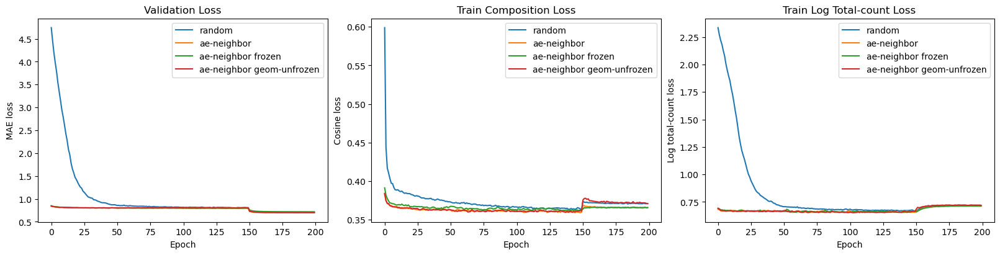

In [13]:
comparison_summary = {
    'Random init': {
        'train': random_coarse_result['train_metrics'],
        'val': random_coarse_result['val_metrics'],
        'test': random_coarse_result['test_metrics'],
    },
    'AE-neighbor init': {
        'train': ae_coarse_result['train_metrics'],
        'val': ae_coarse_result['val_metrics'],
        'test': ae_coarse_result['test_metrics'],
    },
    'AE-neighbor init (decoder frozen)': {
        'train': ae_frozen_coarse_result['train_metrics'],
        'val': ae_frozen_coarse_result['val_metrics'],
        'test': ae_frozen_coarse_result['test_metrics'],
    },
    'AE-neighbor init (geometry unfrozen in MAE)': {
        'train': ae_unfrozen_coarse_result['train_metrics'],
        'val': ae_unfrozen_coarse_result['val_metrics'],
        'test': ae_unfrozen_coarse_result['test_metrics'],
    },
}
print('Coarse training summary')
print(format_for_display(comparison_summary))

fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
axes[0].plot(random_coarse_result['history']['val_loss'], label='random')
axes[0].plot(ae_coarse_result['history']['val_loss'], label='ae-neighbor')
axes[0].plot(ae_frozen_coarse_result['history']['val_loss'], label='ae-neighbor frozen')
axes[0].plot(ae_unfrozen_coarse_result['history']['val_loss'], label='ae-neighbor geom-unfrozen')
axes[0].set_title('Validation Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MAE loss')
axes[0].legend()

axes[1].plot(random_coarse_result['history']['train_composition_loss'], label='random')
axes[1].plot(ae_coarse_result['history']['train_composition_loss'], label='ae-neighbor')
axes[1].plot(ae_frozen_coarse_result['history']['train_composition_loss'], label='ae-neighbor frozen')
axes[1].plot(ae_unfrozen_coarse_result['history']['train_composition_loss'], label='ae-neighbor geom-unfrozen')
axes[1].set_title('Train Composition Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Cosine loss')
axes[1].legend()

axes[2].plot(random_coarse_result['history']['train_total_count_loss'], label='random')
axes[2].plot(ae_coarse_result['history']['train_total_count_loss'], label='ae-neighbor')
axes[2].plot(ae_frozen_coarse_result['history']['train_total_count_loss'], label='ae-neighbor frozen')
axes[2].plot(ae_unfrozen_coarse_result['history']['train_total_count_loss'], label='ae-neighbor geom-unfrozen')
axes[2].set_title('Train Log Total-count Loss')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Log total-count loss')
axes[2].legend()

export_figure_axes(fig, fallback_prefix="merfish_mouse_brain_cell_24_1")
plt.show()


## Coarse Splat Layout Comparison

Compare the active splat locations and true-scale ellipse coverage for the random and AE-neighbor coarse models.


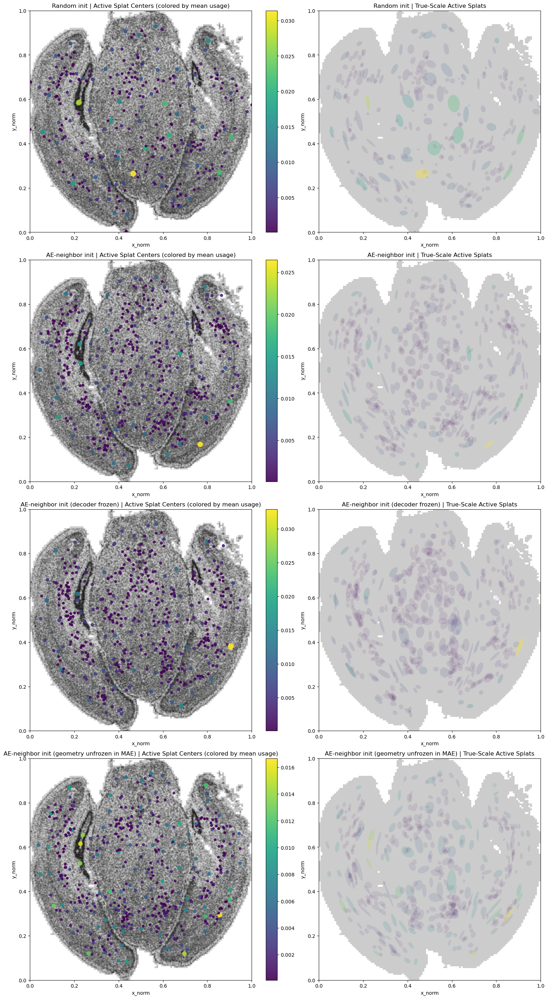

Coarse splat layout summary
{'Random init': {'active_splats': 300, 'total_splats': 512, 'mean_usage_active': 0.003202, 'median_scale_x_active': 0.008716, 'median_scale_y_active': 0.01125, 'mean_peak_usage_active': 0.6222}, 'AE-neighbor init': {'active_splats': 478, 'total_splats': 512, 'mean_usage_active': 0.002027, 'median_scale_x_active': 0.009565, 'median_scale_y_active': 0.01276, 'mean_peak_usage_active': 0.5556}, 'AE-neighbor init (decoder frozen)': {'active_splats': 468, 'total_splats': 512, 'mean_usage_active': 0.002075, 'median_scale_x_active': 0.01037, 'median_scale_y_active': 0.01394, 'mean_peak_usage_active': 0.5142}, 'AE-neighbor init (geometry unfrozen in MAE)': {'active_splats': 458, 'total_splats': 512, 'mean_usage_active': 0.002107, 'median_scale_x_active': 0.009182, 'median_scale_y_active': 0.0132, 'mean_peak_usage_active': 0.5357}}


In [14]:
set_seed(layout_seed)
layout_query_idx = torch.randperm(len(cell_features), device=device)[:min(2048, len(cell_features))]
layout_queries = cell_features[layout_query_idx]

layout_models = [
    ('Random init', random_coarse_result['model']),
    ('AE-neighbor init', ae_coarse_result['model']),
    ('AE-neighbor init (decoder frozen)', ae_frozen_coarse_result['model']),
    ('AE-neighbor init (geometry unfrozen in MAE)', ae_unfrozen_coarse_result['model']),
]

fig, axes = plt.subplots(len(layout_models), 2, figsize=(16, 7 * len(layout_models)), constrained_layout=True)
axes = np.atleast_2d(axes)
layout_summaries = {}

for row, (label, model) in enumerate(layout_models):
    with torch.no_grad():
        layout_weights = compute_splat_weights(model, layout_queries)
        layout_mean_usage = layout_weights.mean(dim=0).detach().cpu().numpy()
        layout_peak_usage = layout_weights.max(dim=0).values.detach().cpu().numpy()
        layout_means = model.means.detach().cpu().numpy()
        layout_scales_xy = torch.exp(model.log_scales).detach().cpu().numpy()
        layout_rotation = model.rotation.detach().cpu().numpy().reshape(-1)

    active_mask = layout_mean_usage > 1e-4
    active_idx = np.flatnonzero(active_mask)
    layout_summaries[label] = {
        'active_splats': int(len(active_idx)),
        'total_splats': int(len(layout_mean_usage)),
        'mean_usage_active': float(layout_mean_usage[active_idx].mean()) if len(active_idx) else float('nan'),
        'median_scale_x_active': float(np.median(layout_scales_xy[active_idx, 0])) if len(active_idx) else float('nan'),
        'median_scale_y_active': float(np.median(layout_scales_xy[active_idx, 1])) if len(active_idx) else float('nan'),
        'mean_peak_usage_active': float(layout_peak_usage[active_idx].mean()) if len(active_idx) else float('nan'),
    }

    ax0 = axes[row, 0]
    ax0.imshow(mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.2)
    ax0.scatter(cell_points_np[:, 0], cell_points_np[:, 1], s=4, alpha=0.08, color='black')
    if len(active_idx):
        sc0 = ax0.scatter(
            layout_means[active_idx, 0],
            layout_means[active_idx, 1],
            c=layout_mean_usage[active_idx],
            s=20.0 + 3000.0 * np.clip(layout_mean_usage[active_idx], 0.0, None),
            cmap='viridis',
            alpha=0.9,
        )
        fig.colorbar(sc0, ax=ax0, fraction=0.046, pad=0.04)
    ax0.set_title(f'{label} | Active Splat Centers (colored by mean usage)')

    ax1 = axes[row, 1]
    ax1.imshow(mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.2)
    draw_order = np.argsort(layout_mean_usage[active_idx]) if len(active_idx) else np.array([], dtype=np.int64)
    for local_pos in draw_order:
        splat_idx = active_idx[local_pos]
        ellipse = Ellipse(
            xy=layout_means[splat_idx],
            width=2.0 * layout_scales_xy[splat_idx, 0],
            height=2.0 * layout_scales_xy[splat_idx, 1],
            angle=float(np.degrees(layout_rotation[splat_idx])),
            facecolor=plt.cm.viridis(min(1.0, max(0.0, layout_mean_usage[splat_idx] / (layout_mean_usage[active_idx].max() + 1e-8)))),
            edgecolor='none',
            alpha=float(np.clip(0.08 + 8.0 * layout_mean_usage[splat_idx], 0.08, 0.75)),
        )
        ax1.add_patch(ellipse)
    ax1.set_title(f'{label} | True-Scale Active Splats')

    for ax in (ax0, ax1):
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect('equal')
        ax.set_xlabel('x_norm')
        ax.set_ylabel('y_norm')

export_figure_axes(fig, fallback_prefix="merfish_mouse_brain_cell_26_1")
plt.show()
print('Coarse splat layout summary')
print(format_for_display(layout_summaries))


## Coarse Overlap Diagnostics

Measure mixture overlap and center spacing more directly for the two coarse models.


In [15]:
set_seed(overlap_seed)
overlap_query_idx = torch.randperm(len(cell_features), device=device)[:min(2048, len(cell_features))]
overlap_queries = cell_features[overlap_query_idx]

coverage_eval_batch_size = 4096

def coverage_mask_for_cells(model, points: torch.Tensor, ellipse_threshold: float = 1.0) -> torch.Tensor:
    means = model.means
    scales = torch.exp(model.log_scales).clamp_min(1e-8)
    theta = model.rotation.squeeze(-1)
    dx = points[:, None, 0] - means[None, :, 0]
    dy = points[:, None, 1] - means[None, :, 1]
    cos_t = torch.cos(theta)[None, :]
    sin_t = torch.sin(theta)[None, :]
    x_local = cos_t * dx + sin_t * dy
    y_local = -sin_t * dx + cos_t * dy
    norm_sq = (x_local / scales[None, :, 0]) ** 2 + (y_local / scales[None, :, 1]) ** 2
    return norm_sq <= float(ellipse_threshold ** 2)


def summarize_covered_usage(model, features: torch.Tensor, mean_usage_active_mask: np.ndarray, usage_threshold: float = 0.01, batch_size: int = coverage_eval_batch_size):
    num_splats = model.num_splats
    covered_count = np.zeros(num_splats, dtype=np.int64)
    covered_usage_sum = np.zeros(num_splats, dtype=np.float64)
    covered_usage_values = [[] for _ in range(num_splats)]
    covered_usage_gt_thresh = np.zeros(num_splats, dtype=np.int64)
    covered_top1 = np.zeros(num_splats, dtype=np.int64)

    with torch.no_grad():
        for start in range(0, len(features), batch_size):
            batch_points = features[start:start + batch_size]
            batch_weights = compute_splat_weights(model, batch_points)
            batch_top1 = batch_weights.argmax(dim=1)
            batch_cover = coverage_mask_for_cells(model, batch_points)

            batch_cover_np = batch_cover.detach().cpu().numpy()
            batch_weights_np = batch_weights.detach().cpu().numpy()
            batch_top1_np = batch_top1.detach().cpu().numpy()

            for splat_idx in range(num_splats):
                covered = batch_cover_np[:, splat_idx]
                if not np.any(covered):
                    continue
                usage_vals = batch_weights_np[covered, splat_idx]
                covered_count[splat_idx] += int(covered.sum())
                covered_usage_sum[splat_idx] += float(usage_vals.sum())
                covered_usage_values[splat_idx].append(usage_vals)
                covered_usage_gt_thresh[splat_idx] += int(np.sum(usage_vals > usage_threshold))
                covered_top1[splat_idx] += int(np.sum(batch_top1_np[covered] == splat_idx))

    covered_mean = np.full(num_splats, np.nan, dtype=np.float64)
    covered_median = np.full(num_splats, np.nan, dtype=np.float64)
    covered_frac_gt = np.full(num_splats, np.nan, dtype=np.float64)
    covered_frac_top1 = np.full(num_splats, np.nan, dtype=np.float64)

    valid_mask = covered_count > 0
    for splat_idx in np.flatnonzero(valid_mask):
        vals = np.concatenate(covered_usage_values[splat_idx]) if covered_usage_values[splat_idx] else np.empty(0, dtype=np.float64)
        if len(vals) == 0:
            continue
        covered_mean[splat_idx] = covered_usage_sum[splat_idx] / float(covered_count[splat_idx])
        covered_median[splat_idx] = float(np.median(vals))
        covered_frac_gt[splat_idx] = covered_usage_gt_thresh[splat_idx] / float(covered_count[splat_idx])
        covered_frac_top1[splat_idx] = covered_top1[splat_idx] / float(covered_count[splat_idx])

    active_and_valid = mean_usage_active_mask & valid_mask
    return {
        'covered_count': covered_count,
        'covered_mean_usage': covered_mean,
        'covered_median_usage': covered_median,
        'covered_fraction_gt_1pct': covered_frac_gt,
        'covered_fraction_top1': covered_frac_top1,
        'active_and_valid_mask': active_and_valid,
    }

overlap_summary = {}
for label, model in layout_models:
    with torch.no_grad():
        overlap_weights = compute_splat_weights(model, overlap_queries)
        usage = usage_statistics(overlap_weights)
        means_np = model.means.detach().cpu().numpy()
        pairwise = np.linalg.norm(means_np[:, None, :] - means_np[None, :, :], axis=-1)
        pairwise[pairwise == 0.0] = np.inf
        nearest_center_dist = pairwise.min(axis=1)
        active_mask_np = overlap_weights.mean(dim=0).detach().cpu().numpy() > 1e-4
        active_nearest = nearest_center_dist[active_mask_np] if np.any(active_mask_np) else np.array([], dtype=np.float64)

    covered_usage = summarize_covered_usage(model, cell_features, active_mask_np)
    active_valid = covered_usage['active_and_valid_mask']

    overlap_summary[label] = {
        'sampled_queries': int(overlap_queries.shape[0]),
        'active_splat_fraction_gt_1e4': float(usage['active_fraction']),
        'dominant_splat_fraction_gt_5pct': float(usage['dominant_fraction']),
        'avg_splats_per_query_gt_1pct': float(usage['avg_splats_per_query_gt_1pct']),
        'median_nearest_center_distance_all': float(np.median(nearest_center_dist)),
        'mean_nearest_center_distance_all': float(np.mean(nearest_center_dist)),
        'median_nearest_center_distance_active': float(np.median(active_nearest)) if len(active_nearest) else float('nan'),
        'mean_nearest_center_distance_active': float(np.mean(active_nearest)) if len(active_nearest) else float('nan'),
        'mean_covered_cell_count_active': float(np.mean(covered_usage['covered_count'][active_valid])) if np.any(active_valid) else float('nan'),
        'median_covered_cell_count_active': float(np.median(covered_usage['covered_count'][active_valid])) if np.any(active_valid) else float('nan'),
        'mean_usage_covered_active': float(np.nanmean(covered_usage['covered_mean_usage'][active_valid])) if np.any(active_valid) else float('nan'),
        'median_usage_covered_active': float(np.nanmedian(covered_usage['covered_median_usage'][active_valid])) if np.any(active_valid) else float('nan'),
        'fraction_covered_usage_gt_1pct_active': float(np.nanmean(covered_usage['covered_fraction_gt_1pct'][active_valid])) if np.any(active_valid) else float('nan'),
        'fraction_covered_top1_active': float(np.nanmean(covered_usage['covered_fraction_top1'][active_valid])) if np.any(active_valid) else float('nan'),
    }

print('Coarse overlap summary')
print(format_for_display(overlap_summary))


Coarse overlap summary
{'Random init': {'sampled_queries': 2048, 'active_splat_fraction_gt_1e4': 0.5762, 'dominant_splat_fraction_gt_5pct': 0.6914, 'avg_splats_per_query_gt_1pct': 2.803, 'median_nearest_center_distance_all': 0.01116, 'mean_nearest_center_distance_all': 0.01417, 'median_nearest_center_distance_active': 0.01312, 'mean_nearest_center_distance_active': 0.01647, 'mean_covered_cell_count_active': 53.21, 'median_covered_cell_count_active': 37.5, 'mean_usage_covered_active': 0.5815, 'median_usage_covered_active': 0.5764, 'fraction_covered_usage_gt_1pct_active': 1.0, 'fraction_covered_top1_active': 0.702}, 'AE-neighbor init': {'sampled_queries': 2048, 'active_splat_fraction_gt_1e4': 0.9434, 'dominant_splat_fraction_gt_5pct': 0.9727, 'avg_splats_per_query_gt_1pct': 3.642, 'median_nearest_center_distance_all': 0.01356, 'mean_nearest_center_distance_all': 0.01647, 'median_nearest_center_distance_active': 0.0139, 'mean_nearest_center_distance_active': 0.01691, 'mean_covered_cell_co

The coverage-based overlap diagnostics show that active splats are locally meaningful even though their global mean usage is diluted across the full tissue. Within the cells geometrically covered by a splat's own ellipse, usage is typically substantial, essentially all active splats exceed the `1%` usage threshold on covered cells, and a large fraction of covered cells treat that splat as the top-weight contributor. That means the splats are not mostly weak or irrelevant to the cells they are supposed to describe.\n
\n
Under this local interpretation, the remaining count artifact is less likely to come from poor local assignment or from distant splats dominating covered cells. Instead, it points more toward the downstream count-readout mechanism: local splat ownership is reasonably strong, but the final cell-level total counts still appear to be compressed when local splat intensities are mixed and averaged back onto cells.\n

## Coarse Amplitude Diagnostics

Compare each coarse model's learned splat amplitudes against the local total-count scale of nearby cells.


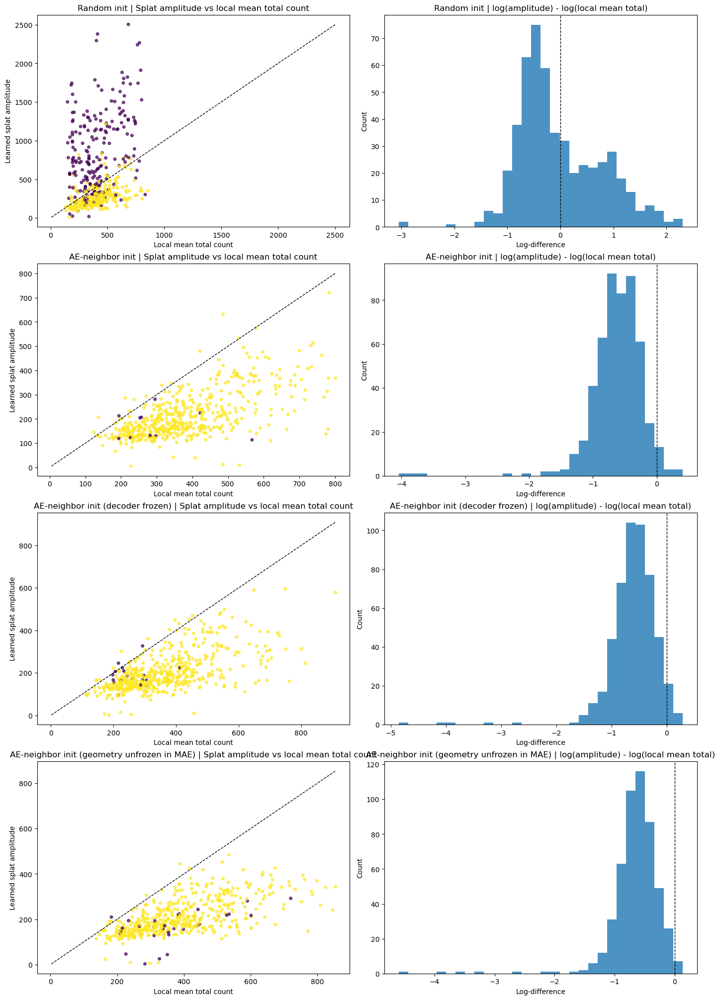

Coarse amplitude summary
{'Random init': {'neighbor_k': 16, 'mean_local_total_count': 403.3, 'mean_local_total_count_std': 276.0, 'median_local_total_count_iqr': 325.0, 'mean_splat_amplitude': 512.4, 'median_splat_amplitude': 314.4, 'median_abs_log_amp_minus_local_mean': 0.5631, 'mean_abs_log_amp_minus_local_mean': 0.6494, 'median_abs_log_amp_minus_local_median': 0.4831, 'mean_abs_log_amp_minus_local_median': 0.6353, 'median_amp_to_local_mean_ratio': 0.7817, 'median_amp_to_local_median_ratio': 1.078, 'active_splats': 299, 'median_abs_log_amp_minus_local_mean_active': 0.5225, 'median_amp_to_local_mean_ratio_active': 0.6123, 'fraction_active_within_1sd_of_local_mean': 0.893, 'fraction_active_within_local_iqr': 0.7458, 'mean_local_total_count_std_active': 275.4, 'median_local_total_count_iqr_active': 325.0}, 'AE-neighbor init': {'neighbor_k': 16, 'mean_local_total_count': 381.3, 'mean_local_total_count_std': 263.5, 'median_local_total_count_iqr': 304.4, 'mean_splat_amplitude': 212.2, 'med

In [16]:
amplitude_diag_neighbor_k = init_neighbor_k
amplitude_summary = {}
fig, axes = plt.subplots(len(layout_models), 2, figsize=(14, 5 * len(layout_models)), constrained_layout=True)
axes = np.atleast_2d(axes)

for row, (label, model) in enumerate(layout_models):
    with torch.no_grad():
        pairwise_dist = torch.cdist(model.means, cell_features)
        neighbor_k = min(amplitude_diag_neighbor_k, cell_features.shape[0])
        _, neighbor_idx = torch.topk(pairwise_dist, k=neighbor_k, largest=False, dim=1)
        local_totals = cell_total_counts[neighbor_idx].squeeze(-1)
        local_mean_totals = local_totals.mean(dim=1)
        local_std_totals = local_totals.std(dim=1, unbiased=False)
        local_median_totals = local_totals.median(dim=1).values
        local_q25_totals = torch.quantile(local_totals, 0.25, dim=1)
        local_q75_totals = torch.quantile(local_totals, 0.75, dim=1)
        splat_amplitudes = model.splat_amplitudes().detach().squeeze(-1)
        mean_usage = compute_splat_weights(model, cell_features).mean(dim=0)
        active_mask = mean_usage > 1e-4

        log_amp = splat_amplitudes.clamp_min(1e-8).log()
        log_local_mean = local_mean_totals.clamp_min(1e-8).log()
        log_local_median = local_median_totals.clamp_min(1e-8).log()
        mean_log_diff = log_amp - log_local_mean
        median_log_diff = log_amp - log_local_median

    active_np = active_mask.detach().cpu().numpy()
    splat_amp_np = splat_amplitudes.detach().cpu().numpy()
    local_mean_np = local_mean_totals.detach().cpu().numpy()
    local_std_np = local_std_totals.detach().cpu().numpy()
    local_median_np = local_median_totals.detach().cpu().numpy()
    local_q25_np = local_q25_totals.detach().cpu().numpy()
    local_q75_np = local_q75_totals.detach().cpu().numpy()
    mean_log_diff_np = mean_log_diff.detach().cpu().numpy()
    median_log_diff_np = median_log_diff.detach().cpu().numpy()

    within_1sd = np.abs(splat_amp_np - local_mean_np) <= local_std_np
    within_iqr = (splat_amp_np >= local_q25_np) & (splat_amp_np <= local_q75_np)

    amplitude_summary[label] = {
        'neighbor_k': int(neighbor_k),
        'mean_local_total_count': float(local_mean_totals.mean().item()),
        'mean_local_total_count_std': float(local_std_totals.mean().item()),
        'median_local_total_count_iqr': float(np.median(local_q75_np - local_q25_np)),
        'mean_splat_amplitude': float(splat_amplitudes.mean().item()),
        'median_splat_amplitude': float(splat_amplitudes.median().item()),
        'median_abs_log_amp_minus_local_mean': float(np.median(np.abs(mean_log_diff_np))),
        'mean_abs_log_amp_minus_local_mean': float(np.mean(np.abs(mean_log_diff_np))),
        'median_abs_log_amp_minus_local_median': float(np.median(np.abs(median_log_diff_np))),
        'mean_abs_log_amp_minus_local_median': float(np.mean(np.abs(median_log_diff_np))),
        'median_amp_to_local_mean_ratio': float(np.median(splat_amp_np / np.clip(local_mean_np, 1e-8, None))),
        'median_amp_to_local_median_ratio': float(np.median(splat_amp_np / np.clip(local_median_np, 1e-8, None))),
        'active_splats': int(active_np.sum()),
        'median_abs_log_amp_minus_local_mean_active': float(np.median(np.abs(mean_log_diff_np[active_np]))) if active_np.any() else float('nan'),
        'median_amp_to_local_mean_ratio_active': float(np.median((splat_amp_np / np.clip(local_mean_np, 1e-8, None))[active_np])) if active_np.any() else float('nan'),
        'fraction_active_within_1sd_of_local_mean': float(np.mean(within_1sd[active_np])) if active_np.any() else float('nan'),
        'fraction_active_within_local_iqr': float(np.mean(within_iqr[active_np])) if active_np.any() else float('nan'),
        'mean_local_total_count_std_active': float(np.mean(local_std_np[active_np])) if active_np.any() else float('nan'),
        'median_local_total_count_iqr_active': float(np.median((local_q75_np - local_q25_np)[active_np])) if active_np.any() else float('nan'),
    }

    ax0 = axes[row, 0]
    ax0.scatter(local_mean_np, splat_amp_np, s=16, alpha=0.7, c=np.where(active_np, 1.0, 0.25), cmap='viridis')
    lo = float(min(local_mean_np.min(), splat_amp_np.min()))
    hi = float(max(local_mean_np.max(), splat_amp_np.max()))
    ax0.plot([lo, hi], [lo, hi], linestyle='--', color='black', linewidth=1.0)
    ax0.set_title(f'{label} | Splat amplitude vs local mean total count')
    ax0.set_xlabel('Local mean total count')
    ax0.set_ylabel('Learned splat amplitude')

    ax1 = axes[row, 1]
    ax1.hist(mean_log_diff_np, bins=30, alpha=0.8, color='tab:blue')
    ax1.axvline(0.0, linestyle='--', color='black', linewidth=1.0)
    ax1.set_title(f'{label} | log(amplitude) - log(local mean total)')
    ax1.set_xlabel('Log-difference')
    ax1.set_ylabel('Count')

export_figure_axes(fig, fallback_prefix="merfish_mouse_brain_cell_31_1")
plt.show()
print('Coarse amplitude summary')
print(format_for_display(amplitude_summary))


In this mouse-brain dataset, the amplitude diagnostics suggest that the main count issue is not that active splats are wildly mis-scaled relative to the cells they cover. The local count distributions around active splats are broad, and most active splat amplitudes still land inside that neighborhood spread: a large majority fall within one local standard deviation of the neighborhood mean, and many also lie within the local interquartile range. That supports the interpretation that splat amplitudes are capturing a plausible local count scale rather than collapsing to obviously nonsensical values.\n
\n
At the same time, the amplitudes are usually below the local center of the neighborhood distribution, with active splats often sitting at only a fraction of the local mean or median total count. So the phenomenon looks less like a purely local amplitude-calibration failure and more like a downstream aggregation or smoothing effect: the splats broadly reflect local regional intensity, but cell-level total counts are still compressed when the field is mixed and averaged back onto cells.\n

## Coarse Total-Count Diagnostics

Check whether the field-level predicted cell total counts are actually worse in the AE-seeded models, or whether the low per-splat amplitudes are just a distributed-representation effect.


Coarse total-count fit summary
{'Random init': {'val': {'n': 7832, 'mae_total_count': 221.2, 'median_abs_total_count_error': 129.7, 'mae_log_total_count': 0.7407, 'median_abs_log_total_count_error': 0.6448, 'corr_total_count': 0.3043, 'corr_log_total_count': 0.1742, 'median_pred_to_true_ratio': 0.6952, 'mean_pred_to_true_ratio': 1.003}, 'test': {'n': 7834, 'mae_total_count': 223.9, 'median_abs_total_count_error': 131.4, 'mae_log_total_count': 0.7657, 'median_abs_log_total_count_error': 0.6545, 'corr_total_count': 0.2779, 'corr_log_total_count': 0.133, 'median_pred_to_true_ratio': 0.697, 'mean_pred_to_true_ratio': 1.004}}, 'AE-neighbor init': {'val': {'n': 7832, 'mae_total_count': 219.5, 'median_abs_total_count_error': 129.6, 'mae_log_total_count': 0.7293, 'median_abs_log_total_count_error': 0.6316, 'corr_total_count': 0.313, 'corr_log_total_count': 0.187, 'median_pred_to_true_ratio': 0.6988, 'mean_pred_to_true_ratio': 1.009}, 'test': {'n': 7834, 'mae_total_count': 222.2, 'median_abs_to

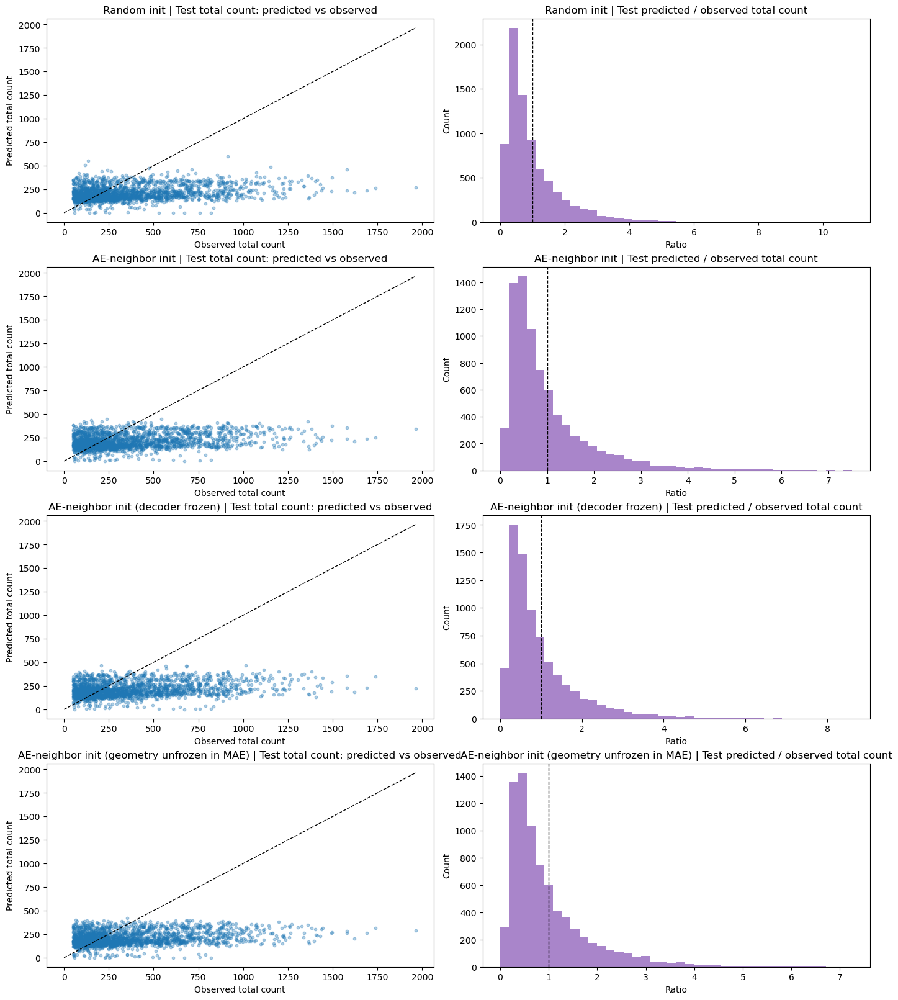

In [17]:
def evaluate_total_count_fit(model, idx: torch.Tensor, batch_size: int = 512):
    was_training = model.training
    model.eval()
    pred_total_chunks = []
    true_total_chunks = []
    with torch.no_grad():
        for start in range(0, len(idx), batch_size):
            batch_idx = idx[start:start + batch_size]
            pred_log_rate = splat_cell_readout_fn(
                model,
                cell_features[batch_idx],
                cell_spans[batch_idx],
                batch_size=batch_size,
            )
            pred_total_chunks.append(torch.exp(pred_log_rate).sum(dim=1))
            true_total_chunks.append(cell_targets[batch_idx].sum(dim=1))
    if was_training:
        model.train()
    pred_total = torch.cat(pred_total_chunks, dim=0).detach().cpu().numpy()
    true_total = torch.cat(true_total_chunks, dim=0).detach().cpu().numpy()
    log_pred = np.log(np.clip(pred_total, 1e-8, None))
    log_true = np.log(np.clip(true_total, 1e-8, None))
    ratio = pred_total / np.clip(true_total, 1e-8, None)
    return {
        'n': int(len(true_total)),
        'pred_total': pred_total,
        'true_total': true_total,
        'mae_total_count': float(np.mean(np.abs(pred_total - true_total))),
        'median_abs_total_count_error': float(np.median(np.abs(pred_total - true_total))),
        'mae_log_total_count': float(np.mean(np.abs(log_pred - log_true))),
        'median_abs_log_total_count_error': float(np.median(np.abs(log_pred - log_true))),
        'corr_total_count': float(np.corrcoef(pred_total, true_total)[0, 1]) if len(true_total) > 1 and np.std(pred_total) > 0 and np.std(true_total) > 0 else float('nan'),
        'corr_log_total_count': float(np.corrcoef(log_pred, log_true)[0, 1]) if len(true_total) > 1 and np.std(log_pred) > 0 and np.std(log_true) > 0 else float('nan'),
        'median_pred_to_true_ratio': float(np.median(ratio)),
        'mean_pred_to_true_ratio': float(np.mean(ratio)),
    }

count_fit_summary = {}
count_fit_store = {}
for label, model in layout_models:
    val_fit = evaluate_total_count_fit(model, cell_val_idx)
    test_fit = evaluate_total_count_fit(model, cell_test_idx)
    count_fit_store[label] = {'val': val_fit, 'test': test_fit}
    count_fit_summary[label] = {
        'val': {k: v for k, v in val_fit.items() if k not in {'pred_total', 'true_total'}},
        'test': {k: v for k, v in test_fit.items() if k not in {'pred_total', 'true_total'}},
    }

print('Coarse total-count fit summary')
print(format_for_display(count_fit_summary))

fig, axes = plt.subplots(len(layout_models), 2, figsize=(14, 4 * len(layout_models)), constrained_layout=True)
axes = np.atleast_2d(axes)
for row, (label, _) in enumerate(layout_models):
    test_fit = count_fit_store[label]['test']
    pred_total = test_fit['pred_total']
    true_total = test_fit['true_total']
    sample_n = min(2048, len(true_total))
    sample_idx = np.linspace(0, len(true_total) - 1, sample_n, dtype=int)
    x_true = true_total[sample_idx]
    y_pred = pred_total[sample_idx]

    ax0 = axes[row, 0]
    ax0.scatter(x_true, y_pred, s=10, alpha=0.35)
    lo = float(min(x_true.min(), y_pred.min()))
    hi = float(max(x_true.max(), y_pred.max()))
    ax0.plot([lo, hi], [lo, hi], linestyle='--', color='black', linewidth=1.0)
    ax0.set_title(f'{label} | Test total count: predicted vs observed')
    ax0.set_xlabel('Observed total count')
    ax0.set_ylabel('Predicted total count')

    ax1 = axes[row, 1]
    ratio = pred_total / np.clip(true_total, 1e-8, None)
    ax1.hist(ratio, bins=40, alpha=0.8, color='tab:purple')
    ax1.axvline(1.0, linestyle='--', color='black', linewidth=1.0)
    ax1.set_title(f'{label} | Test predicted / observed total count')
    ax1.set_xlabel('Ratio')
    ax1.set_ylabel('Count')

export_figure_axes(fig, fallback_prefix="merfish_mouse_brain_cell_34_1")
plt.show()


## Coarse Program Drift Diagnostics

Compare decoded splat programs before and after coarse training to see whether the AE-initialized biological programs stay coherent after decoder fine-tuning.


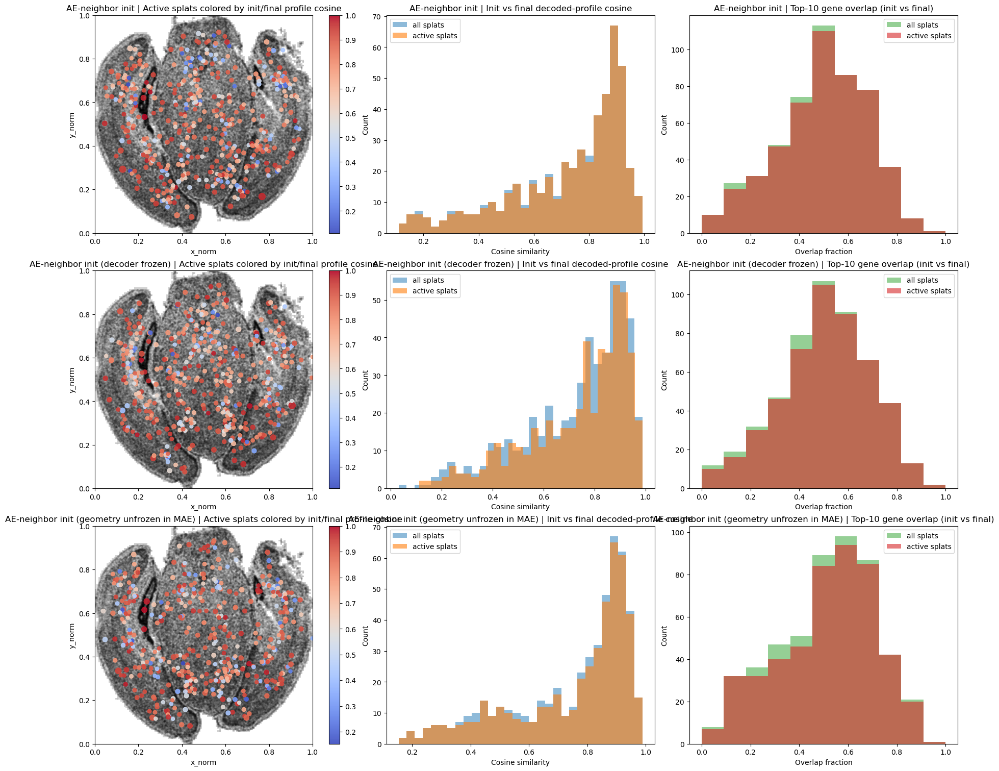

Coarse program drift summary
{'AE-neighbor init': {'active_splats': 502, 'mean_profile_cosine_all': 0.7227, 'median_profile_cosine_all': 0.7961, 'mean_profile_cosine_active': 0.726, 'median_profile_cosine_active': 0.8004, 'mean_top10_overlap_all': 0.4934, 'median_top10_overlap_all': 0.5, 'mean_top10_overlap_active': 0.4966, 'median_top10_overlap_active': 0.5, 'program_geometry_corr_active': 0.3373}, 'AE-neighbor init (decoder frozen)': {'active_splats': 494, 'mean_profile_cosine_all': 0.7271, 'median_profile_cosine_all': 0.783, 'mean_profile_cosine_active': 0.7354, 'median_profile_cosine_active': 0.7908, 'mean_top10_overlap_all': 0.5023, 'median_top10_overlap_all': 0.5, 'mean_top10_overlap_active': 0.5097, 'median_top10_overlap_active': 0.5, 'program_geometry_corr_active': 0.3804}, 'AE-neighbor init (geometry unfrozen in MAE)': {'active_splats': 483, 'mean_profile_cosine_all': 0.7467, 'median_profile_cosine_all': 0.8338, 'mean_profile_cosine_active': 0.7511, 'median_profile_cosine_acti

In [18]:
with torch.no_grad():
    init_gene_logits, _ = encoder_initialized_splat_model.decoder(encoder_initialized_splat_model.latents)
    init_profiles = torch.softmax(init_gene_logits, dim=1)

program_drift_models = [
    ('AE-neighbor init', ae_coarse_result['model']),
    ('AE-neighbor init (decoder frozen)', ae_frozen_coarse_result['model']),
    ('AE-neighbor init (geometry unfrozen in MAE)', ae_unfrozen_coarse_result['model']),
]

top_gene_k = min(10, num_genes)
program_drift_summary = {}
fig, axes = plt.subplots(len(program_drift_models), 3, figsize=(18, 5 * len(program_drift_models)), constrained_layout=True)
axes = np.atleast_2d(axes)

for row, (label, model) in enumerate(program_drift_models):
    with torch.no_grad():
        final_gene_logits, _ = model.decoder(model.latents)
        final_profiles = torch.softmax(final_gene_logits, dim=1)
        init_norm = init_profiles / init_profiles.norm(dim=1, keepdim=True).clamp_min(1e-8)
        final_norm = final_profiles / final_profiles.norm(dim=1, keepdim=True).clamp_min(1e-8)
        profile_cosine = (init_norm * final_norm).sum(dim=1)
        mean_usage = compute_splat_weights(model, cell_features).mean(dim=0)
        active_mask = mean_usage > 1e-4

        init_top = torch.topk(init_profiles, k=top_gene_k, dim=1).indices.detach().cpu().numpy()
        final_top = torch.topk(final_profiles, k=top_gene_k, dim=1).indices.detach().cpu().numpy()
        top_overlap = np.array([
            len(set(init_top[i].tolist()) & set(final_top[i].tolist())) / float(top_gene_k)
            for i in range(init_top.shape[0])
        ], dtype=np.float64)

        active_idx = torch.nonzero(active_mask, as_tuple=False).squeeze(1)
        if active_idx.numel() >= 2:
            init_active = init_norm[active_idx]
            final_active = final_norm[active_idx]
            init_pairwise = (init_active @ init_active.T).detach().cpu().numpy()
            final_pairwise = (final_active @ final_active.T).detach().cpu().numpy()
            tri = np.triu_indices(init_pairwise.shape[0], k=1)
            if len(tri[0]) > 1 and np.std(init_pairwise[tri]) > 0 and np.std(final_pairwise[tri]) > 0:
                program_geometry_corr = float(np.corrcoef(init_pairwise[tri], final_pairwise[tri])[0, 1])
            else:
                program_geometry_corr = float('nan')
        else:
            program_geometry_corr = float('nan')

    profile_cosine_np = profile_cosine.detach().cpu().numpy()
    mean_usage_np = mean_usage.detach().cpu().numpy()
    active_np = active_mask.detach().cpu().numpy()
    means_np = model.means.detach().cpu().numpy()

    program_drift_summary[label] = {
        'active_splats': int(active_np.sum()),
        'mean_profile_cosine_all': float(np.mean(profile_cosine_np)),
        'median_profile_cosine_all': float(np.median(profile_cosine_np)),
        'mean_profile_cosine_active': float(np.mean(profile_cosine_np[active_np])) if active_np.any() else float('nan'),
        'median_profile_cosine_active': float(np.median(profile_cosine_np[active_np])) if active_np.any() else float('nan'),
        'mean_top10_overlap_all': float(np.mean(top_overlap)),
        'median_top10_overlap_all': float(np.median(top_overlap)),
        'mean_top10_overlap_active': float(np.mean(top_overlap[active_np])) if active_np.any() else float('nan'),
        'median_top10_overlap_active': float(np.median(top_overlap[active_np])) if active_np.any() else float('nan'),
        'program_geometry_corr_active': program_geometry_corr,
    }

    ax0 = axes[row, 0]
    ax0.imshow(mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.18)
    ax0.scatter(cell_points_np[:, 0], cell_points_np[:, 1], s=4, alpha=0.06, color='black')
    if active_np.any():
        sc0 = ax0.scatter(
            means_np[active_np, 0],
            means_np[active_np, 1],
            c=profile_cosine_np[active_np],
            s=25.0 + 2500.0 * np.clip(mean_usage_np[active_np], 0.0, None),
            cmap='coolwarm',
            alpha=0.9,
            vmin=max(0.0, float(np.nanmin(profile_cosine_np[active_np]))),
            vmax=1.0,
        )
        fig.colorbar(sc0, ax=ax0, fraction=0.046, pad=0.04)
    ax0.set_title(f'{label} | Active splats colored by init/final profile cosine')
    ax0.set_xlim(0, 1)
    ax0.set_ylim(0, 1)
    ax0.set_aspect('equal')
    ax0.set_xlabel('x_norm')
    ax0.set_ylabel('y_norm')

    ax1 = axes[row, 1]
    cosine_all = profile_cosine_np[np.isfinite(profile_cosine_np)]
    cosine_active = profile_cosine_np[active_np] if active_np.any() else np.empty(0, dtype=np.float64)
    cosine_active = cosine_active[np.isfinite(cosine_active)]
    if len(cosine_all):
        cosine_min = float(np.min(cosine_all))
        cosine_max = float(np.max(cosine_all))
        if np.isclose(cosine_min, cosine_max):
            cosine_bins = max(1, min(10, len(np.unique(np.round(cosine_all, decimals=6)))))
        else:
            cosine_bins = 30
        ax1.hist(cosine_all, bins=cosine_bins, alpha=0.5, label='all splats', color='tab:blue')
        if len(cosine_active):
            ax1.hist(cosine_active, bins=cosine_bins, alpha=0.6, label='active splats', color='tab:orange')
    else:
        ax1.text(0.5, 0.5, 'No finite cosine values', ha='center', va='center', transform=ax1.transAxes)
    ax1.set_title(f'{label} | Init vs final decoded-profile cosine')
    ax1.set_xlabel('Cosine similarity')
    ax1.set_ylabel('Count')
    ax1.legend()

    ax2 = axes[row, 2]
    ax2.hist(top_overlap, bins=np.linspace(0.0, 1.0, top_gene_k + 2), alpha=0.5, label='all splats', color='tab:green')
    if active_np.any():
        ax2.hist(top_overlap[active_np], bins=np.linspace(0.0, 1.0, top_gene_k + 2), alpha=0.6, label='active splats', color='tab:red')
    ax2.set_title(f'{label} | Top-{top_gene_k} gene overlap (init vs final)')
    ax2.set_xlabel('Overlap fraction')
    ax2.set_ylabel('Count')
    ax2.legend()

export_figure_axes(fig, fallback_prefix="merfish_mouse_brain_cell_36_1")
plt.show()
print('Coarse program drift summary')
print(format_for_display(program_drift_summary))


## Cellular Program Analysis

Cluster the active decoded splat programs from the AE-neighbor coarse model and visualize their spatial arrangement, amplitude, and true-scale support.


AE-neighbor coarse active splats for program clustering: 480 / 512
Per-Splat Amplitudes
{'all_splats': {'mean': 212.2, 'std': 95.11, 'min': 4.862, 'median': 184.2, 'q90': 354.1, 'q99': 501.6, 'max': 720.8}, 'active_splats': {'mean': 214.9, 'std': 96.53, 'min': 4.862, 'median': 185.3, 'q90': 358.7, 'q99': 504.7, 'max': 720.8}, 'corr_mean_usage_vs_total_intensity': 0.01867, 'corr_peak_usage_vs_total_intensity': -0.03455}


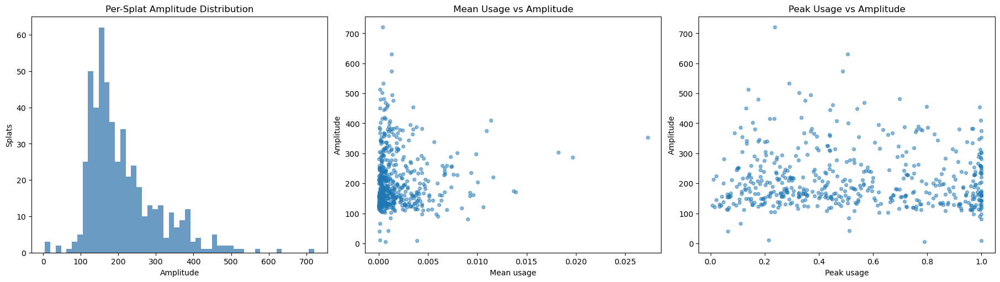

{'chosen_k': 8}


/home/javeda/miniconda3/envs/spatsplat/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/javeda/miniconda3/envs/spatsplat/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


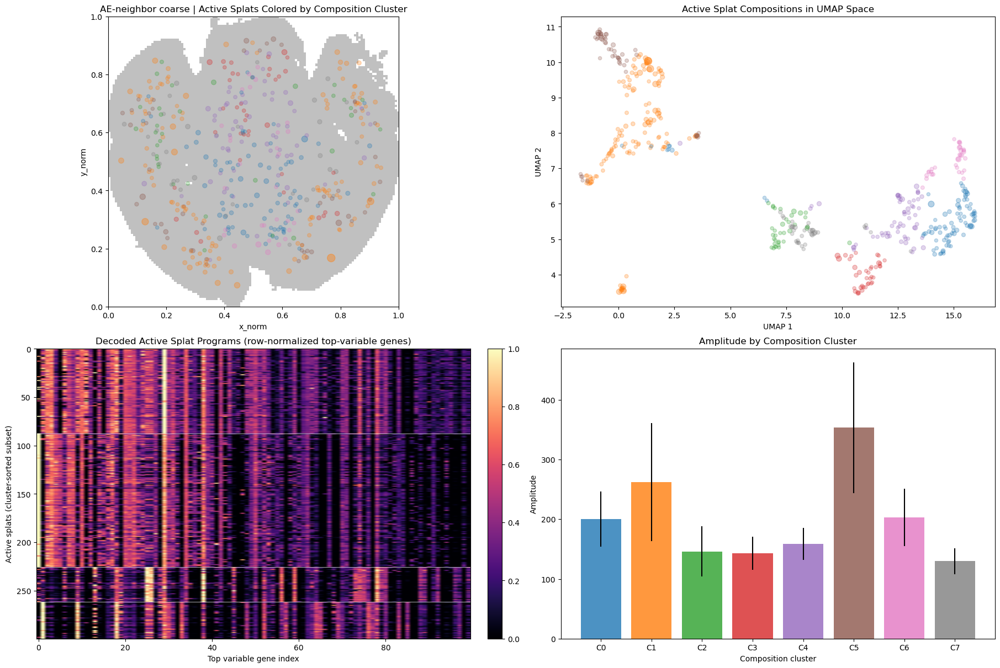

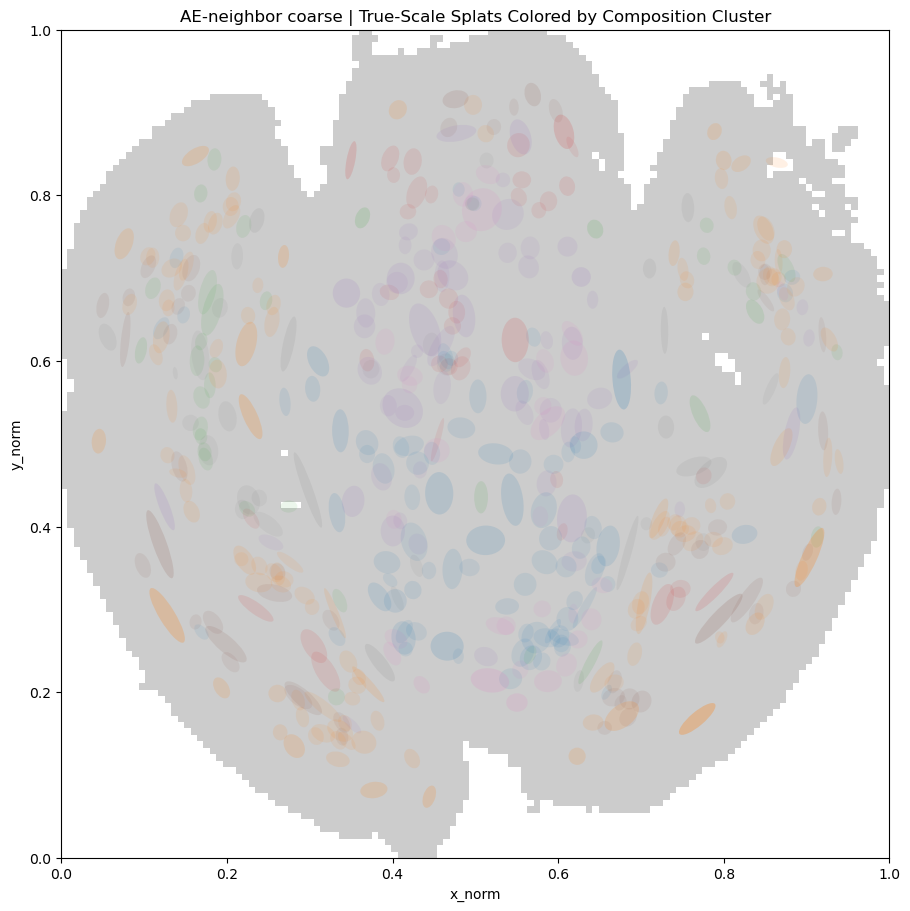

Shared Program Clusters (composition-based)
{'cluster_0': {'n_splats': 88, 'mean_usage': 0.001878, 'mean_opacity': 0.4956, 'mean_amplitude': 199.9, 'top_genes_by_composition': ['Gabbr1', 'Cspg5', 'Gprc5b', 'Cx3cl1', 'Syt4']}, 'cluster_1': {'n_splats': 138, 'mean_usage': 0.002608, 'mean_opacity': 0.5012, 'mean_amplitude': 262.0, 'top_genes_by_composition': ['Slc17a7', 'Gabbr1', 'Cx3cl1', 'Cspg5', 'Syt4']}, 'cluster_2': {'n_splats': 36, 'mean_usage': 0.001293, 'mean_opacity': 0.4653, 'mean_amplitude': 146.2, 'top_genes_by_composition': ['Ntsr2', 'Cspg5', 'Gpr37l1', 'Ntrk2', 'Gabbr1']}, 'cluster_3': {'n_splats': 39, 'mean_usage': 0.001724, 'mean_opacity': 0.4674, 'mean_amplitude': 142.7, 'top_genes_by_composition': ['Gjc3', 'Olig1', 'Gprc5b', 'Gabbr1', 'Fgfr2']}, 'cluster_4': {'n_splats': 62, 'mean_usage': 0.001802, 'mean_opacity': 0.4988, 'mean_amplitude': 158.7, 'top_genes_by_composition': ['Gabbr1', 'Gjc3', 'Gprc5b', 'Olig1', 'Ntsr2']}, 'cluster_5': {'n_splats': 50, 'mean_usage': 0.001

In [19]:
program_usage_query_idx = torch.randperm(len(cell_features), device=device)[:min(2048, len(cell_features))]
program_queries = cell_features[program_usage_query_idx]
program_model = ae_coarse_result['model']
program_label = 'AE-neighbor coarse'
program_n_clusters = min(8, splat_cfg.num_splats)

with torch.no_grad():
    program_weights = compute_splat_weights(program_model, program_queries)
    program_mean_usage = program_weights.mean(dim=0).detach().cpu().numpy()
    program_peak_usage = program_weights.max(dim=0).values.detach().cpu().numpy()

    gene_logits, _ = program_model.decoder(program_model.latents)
    program_composition = torch.softmax(gene_logits, dim=-1).detach().cpu().numpy()
    program_total_intensity = program_model.splat_amplitudes().detach().cpu().numpy().reshape(-1)
    program_rates = program_total_intensity[:, None] * program_composition

    program_means = program_model.means.detach().cpu().numpy()
    program_scales_xy = torch.exp(program_model.log_scales).detach().cpu().numpy()
    program_scales = program_scales_xy.mean(axis=1)
    program_rotation = program_model.rotation.detach().cpu().numpy().reshape(-1)
    program_opacity = torch.sigmoid(program_model.opacity_logits).squeeze(-1).detach().cpu().numpy()

active_mask = program_mean_usage > 1e-4
active_idx = np.flatnonzero(active_mask)
print(f'{program_label} active splats for program clustering: {len(active_idx)} / {len(program_mean_usage)}')

program_amplitude_summary = {
    'all_splats': {
        'mean': float(program_total_intensity.mean()),
        'std': float(program_total_intensity.std()),
        'min': float(program_total_intensity.min()),
        'median': float(np.median(program_total_intensity)),
        'q90': float(np.quantile(program_total_intensity, 0.90)),
        'q99': float(np.quantile(program_total_intensity, 0.99)),
        'max': float(program_total_intensity.max()),
    },
    'active_splats': {
        'mean': float(program_total_intensity[active_idx].mean()) if len(active_idx) else float('nan'),
        'std': float(program_total_intensity[active_idx].std()) if len(active_idx) else float('nan'),
        'min': float(program_total_intensity[active_idx].min()) if len(active_idx) else float('nan'),
        'median': float(np.median(program_total_intensity[active_idx])) if len(active_idx) else float('nan'),
        'q90': float(np.quantile(program_total_intensity[active_idx], 0.90)) if len(active_idx) else float('nan'),
        'q99': float(np.quantile(program_total_intensity[active_idx], 0.99)) if len(active_idx) else float('nan'),
        'max': float(program_total_intensity[active_idx].max()) if len(active_idx) else float('nan'),
    },
    'corr_mean_usage_vs_total_intensity': float(np.corrcoef(program_mean_usage, program_total_intensity)[0, 1]) if len(program_mean_usage) > 1 else float('nan'),
    'corr_peak_usage_vs_total_intensity': float(np.corrcoef(program_peak_usage, program_total_intensity)[0, 1]) if len(program_peak_usage) > 1 else float('nan'),
}
print('Per-Splat Amplitudes')
print(format_for_display(program_amplitude_summary))

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
axes[0].hist(program_total_intensity, bins=50, color='steelblue', alpha=0.8)
axes[0].set_title('Per-Splat Amplitude Distribution')
axes[0].set_xlabel('Amplitude')
axes[0].set_ylabel('Splats')

axes[1].scatter(program_mean_usage, program_total_intensity, s=18, alpha=0.5)
axes[1].set_title('Mean Usage vs Amplitude')
axes[1].set_xlabel('Mean usage')
axes[1].set_ylabel('Amplitude')

axes[2].scatter(program_peak_usage, program_total_intensity, s=18, alpha=0.5)
axes[2].set_title('Peak Usage vs Amplitude')
axes[2].set_xlabel('Peak usage')
axes[2].set_ylabel('Amplitude')
export_figure_axes(fig, fallback_prefix="merfish_mouse_brain_cell_38_1")
plt.show()

if len(active_idx) < 3:
    print('Not enough active splats to cluster decoded programs.')
else:
    from sklearn.cluster import KMeans
    from sklearn.decomposition import PCA

    active_compositions = program_composition[active_idx]
    active_log_rates = np.log1p(program_rates[active_idx])
    active_intensity = program_total_intensity[active_idx]
    n_clusters = min(program_n_clusters, len(active_idx))
    if n_clusters < 2:
        n_clusters = 2

    print(format_for_display({'chosen_k': int(n_clusters)}))
    program_clusters = KMeans(n_clusters=n_clusters, n_init=10, random_state=0).fit_predict(active_compositions)

    try:
        import umap
        reducer = umap.UMAP(n_components=2, random_state=0)
        embedding = reducer.fit_transform(active_compositions)
        embedding_label = 'UMAP'
    except ImportError:
        reducer = PCA(n_components=2, random_state=0)
        embedding = reducer.fit_transform(active_compositions)
        embedding_label = 'PCA fallback (umap-learn not installed)'

    cluster_top = {}
    for cluster_id in range(n_clusters):
        cluster_mean = active_compositions[program_clusters == cluster_id].mean(axis=0)
        top_idx = np.argsort(cluster_mean)[-5:][::-1]
        cluster_top[cluster_id] = [gene_list[i] for i in top_idx]

    cluster_colors = plt.cm.tab10(np.arange(n_clusters) % 10)
    point_colors = cluster_colors[program_clusters]
    scatter_size = 20.0 + 3000.0 * np.clip(program_mean_usage[active_idx], 0.0, None)
    scatter_alpha = np.clip(0.25 + 6.0 * program_mean_usage[active_idx], 0.25, 0.95)

    fig, axes = plt.subplots(2, 2, figsize=(18, 12), constrained_layout=True)
    axes[0, 0].imshow(mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.25)
    axes[0, 0].scatter(
        program_means[active_idx, 0],
        program_means[active_idx, 1],
        color=point_colors,
        s=scatter_size,
        alpha=scatter_alpha,
    )
    axes[0, 0].set_title(f'{program_label} | Active Splats Colored by Composition Cluster')
    axes[0, 0].set_xlim(0, 1)
    axes[0, 0].set_ylim(0, 1)
    axes[0, 0].set_aspect('equal')
    axes[0, 0].set_xlabel('x_norm')
    axes[0, 0].set_ylabel('y_norm')

    axes[0, 1].scatter(
        embedding[:, 0],
        embedding[:, 1],
        color=point_colors,
        s=scatter_size,
        alpha=scatter_alpha,
    )
    axes[0, 1].set_title(f'Active Splat Compositions in {embedding_label} Space')
    axes[0, 1].set_xlabel(f'{embedding_label} 1')
    axes[0, 1].set_ylabel(f'{embedding_label} 2')

    order = np.argsort(program_clusters)
    sample_cap = min(300, len(active_idx))
    show_order = order[:sample_cap]
    show_clusters = program_clusters[show_order]
    variable_gene_k = min(100, active_log_rates.shape[1])
    variable_gene_idx = np.argsort(active_log_rates.var(axis=0))[::-1][:variable_gene_k]
    show_programs = active_log_rates[show_order][:, variable_gene_idx]
    show_programs_row_norm = show_programs / np.clip(show_programs.max(axis=1, keepdims=True), 1e-8, None)
    im = axes[1, 0].imshow(show_programs_row_norm, aspect='auto', cmap='magma', vmin=0.0, vmax=1.0)
    axes[1, 0].set_title('Decoded Active Splat Programs (row-normalized top-variable genes)')
    axes[1, 0].set_xlabel('Top variable gene index')
    axes[1, 0].set_ylabel('Active splats (cluster-sorted subset)')
    cluster_breaks = np.where(np.diff(show_clusters) != 0)[0]
    for boundary in cluster_breaks:
        axes[1, 0].axhline(boundary + 0.5, color='white', linewidth=0.7, alpha=0.7)
    fig.colorbar(im, ax=axes[1, 0], fraction=0.046, pad=0.04)

    intensity_means = [active_intensity[program_clusters == cluster_id].mean() for cluster_id in range(n_clusters)]
    intensity_stds = [active_intensity[program_clusters == cluster_id].std() for cluster_id in range(n_clusters)]
    axes[1, 1].bar(np.arange(n_clusters), intensity_means, yerr=intensity_stds, color=cluster_colors, alpha=0.8)
    axes[1, 1].set_title('Amplitude by Composition Cluster')
    axes[1, 1].set_xlabel('Composition cluster')
    axes[1, 1].set_ylabel('Amplitude')
    axes[1, 1].set_xticks(np.arange(n_clusters))
    axes[1, 1].set_xticklabels([f'C{cluster_id}' for cluster_id in range(n_clusters)])
    export_figure_axes(fig, fallback_prefix="merfish_mouse_brain_cell_38_2")
    plt.show()

    draw_order = np.argsort(program_mean_usage[active_idx])
    fig, ax = plt.subplots(1, 1, figsize=(9, 9), constrained_layout=True)
    ax.imshow(mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.2)
    for local_idx in draw_order:
        splat_idx = active_idx[local_idx]
        cluster_id = int(program_clusters[local_idx])
        ellipse = Ellipse(
            xy=program_means[splat_idx],
            width=2.0 * program_scales_xy[splat_idx, 0],
            height=2.0 * program_scales_xy[splat_idx, 1],
            angle=float(np.degrees(program_rotation[splat_idx])),
            facecolor=cluster_colors[cluster_id],
            edgecolor='none',
            alpha=float(np.clip(0.08 + 8.0 * program_mean_usage[splat_idx], 0.08, 0.75)),
        )
        ax.add_patch(ellipse)
    ax.set_title(f'{program_label} | True-Scale Splats Colored by Composition Cluster')
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal')
    ax.set_xlabel('x_norm')
    ax.set_ylabel('y_norm')
    export_figure_axes(fig, fallback_prefix="merfish_mouse_brain_cell_38_3")
    plt.show()

    print('Shared Program Clusters (composition-based)')
    cluster_program_summary = {}
    for cluster_id in range(n_clusters):
        cluster_mask = program_clusters == cluster_id
        cluster_program_summary[f'cluster_{cluster_id}'] = {
            'n_splats': int(cluster_mask.sum()),
            'mean_usage': float(program_mean_usage[active_idx][cluster_mask].mean()),
            'mean_opacity': float(program_opacity[active_idx][cluster_mask].mean()),
            'mean_amplitude': float(active_intensity[cluster_mask].mean()),
            'top_genes_by_composition': cluster_top[cluster_id],
        }
    print(format_for_display(cluster_program_summary))


## Baseline Comparison Analysis

Compare the AE-neighbor coarse splat model against the trained baselines using the same spatial and per-cell diagnostics used in the modular amplitude notebooks.


Note: In this MERFISH mouse-brain dataset, overall MAE slightly favors the strongest MLP baselines, but the count-stratified analysis is more informative than the pooled metric. The MLPs perform better in the lower total-count quartiles, while the splat models perform better in the higher-count quartiles, where the reconstruction problem is harder and the cells are typically more information-rich. The splat models also retain stronger cosine similarity, so the result should be interpreted as a tradeoff in model bias rather than a simple loss on reconstruction quality.


Comparison Gene: Slc17a7
Edge vs Interior Error
AE-neighbor splat {'edge_thresh': 0.05444, 'interior_thresh': 0.1457, 'edge_mae': 0.6586, 'interior_mae': 0.6998, 'overall_mae': 0.7029, 'edge_n': 1959, 'interior_n': 1959}
AE-neighbor splat {'active_n': 4412, 'inactive_n': 3422, 'active_true_mean': 42.21, 'inactive_true_mean': 0.0, 'active_signed_error_mean': -13.74, 'inactive_signed_error_mean': 2.966, 'active_abs_error_mean': 32.48, 'inactive_abs_error_mean': 2.966}
MLP-MAE {'edge_thresh': 0.05444, 'interior_thresh': 0.1457, 'edge_mae': 0.6793, 'interior_mae': 0.6943, 'overall_mae': 0.7156, 'edge_n': 1959, 'interior_n': 1959}
MLP-MAE {'active_n': 4412, 'inactive_n': 3422, 'active_true_mean': 42.21, 'inactive_true_mean': 0.0, 'active_signed_error_mean': -33.99, 'inactive_signed_error_mean': 1.996, 'active_abs_error_mean': 38.08, 'inactive_abs_error_mean': 1.996}
MLP (Bio Objective) {'edge_thresh': 0.05444, 'interior_thresh': 0.1457, 'edge_mae': 0.7037, 'interior_mae': 0.7205, 'overall_m

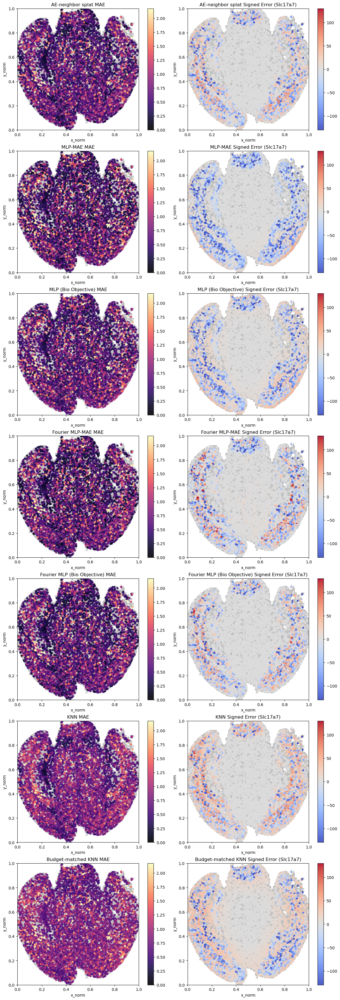

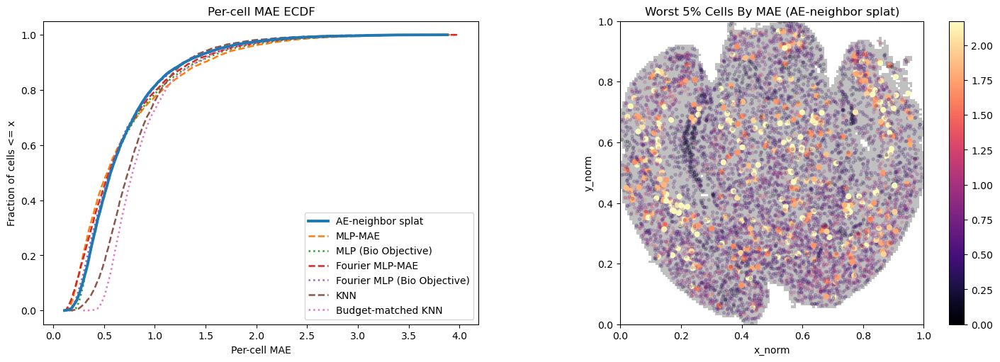

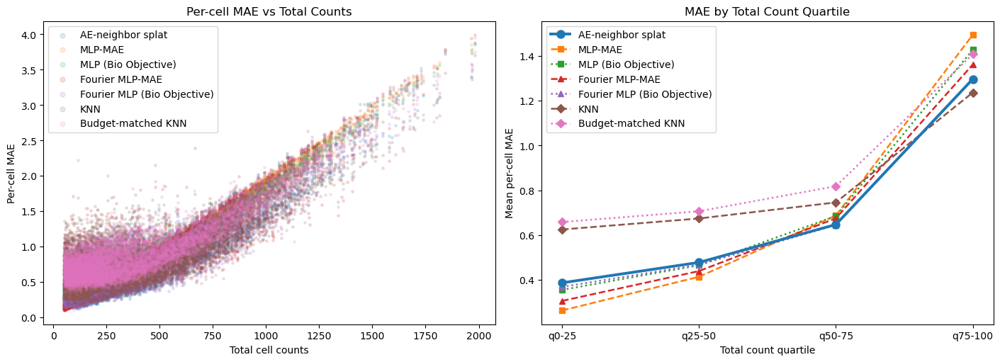

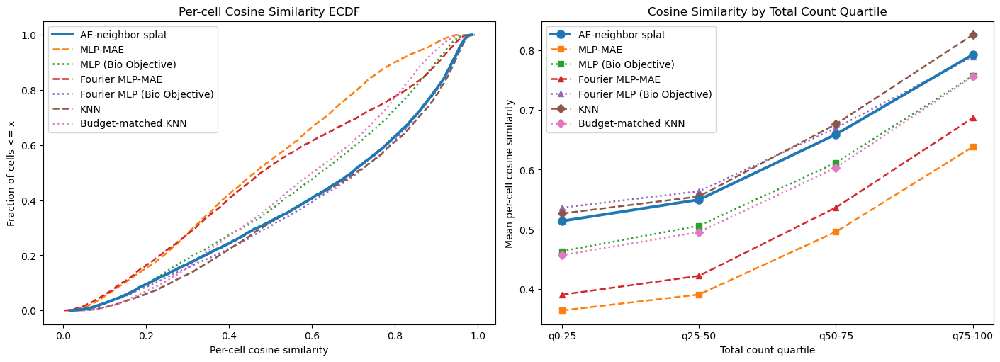

In [20]:
comparison_gene_name = comparison_gene_of_interest if comparison_gene_of_interest in gene_to_id else ('Slc17a7' if 'Slc17a7' in gene_to_id else gene_list[0])
comparison_gene_idx = gene_to_id[comparison_gene_name]

comparison_mask_np = tissue_mask_tensor.squeeze().detach().cpu().numpy() > 0.05
comparison_distance_map = distance_transform_edt(comparison_mask_np).astype(np.float32) / data_cfg.mask_grid_size

def predict_counts_cell_model(model, features, spans, batch_size=512):
    was_training = model.training
    model.eval()
    outs = []
    with torch.no_grad():
        for start in range(0, len(features), batch_size):
            outs.append(torch.exp(splat_cell_readout_fn(model, features[start:start + batch_size], spans[start:start + batch_size], batch_size=batch_size)))
    if was_training:
        model.train()
    return torch.cat(outs, dim=0)


def predict_counts_direct_model(model, features, batch_size=256):
    was_training = model.training
    model.eval()
    outs = []
    with torch.no_grad():
        for start in range(0, len(features), batch_size):
            outs.append(torch.exp(model(features[start:start + batch_size])))
    if was_training:
        model.train()
    return torch.cat(outs, dim=0)


def per_cell_cosine_similarity(pred_counts, true_counts):
    pred_norm = pred_counts / pred_counts.norm(dim=1, keepdim=True).clamp_min(1e-8)
    true_norm = true_counts / true_counts.norm(dim=1, keepdim=True).clamp_min(1e-8)
    return (pred_norm * true_norm).sum(dim=1).detach().cpu().numpy()


def summarize_count_conditioned_error(total_counts, mae_values):
    q_edges = np.quantile(total_counts, [0.0, 0.25, 0.5, 0.75, 1.0])
    q_edges[0] = np.floor(q_edges[0])
    q_edges[-1] = np.ceil(q_edges[-1])
    labels = ['q0-25', 'q25-50', 'q50-75', 'q75-100']
    out = {}
    for i, label in enumerate(labels):
        lo = q_edges[i]
        hi = q_edges[i + 1]
        if i == len(labels) - 1:
            mask = (total_counts >= lo) & (total_counts <= hi)
        else:
            mask = (total_counts >= lo) & (total_counts < hi)
        out[label] = {
            'count_range': [float(lo), float(hi)],
            'n': int(mask.sum()),
            'mean_mae': float(mae_values[mask].mean()) if mask.any() else float('nan'),
            'median_mae': float(np.median(mae_values[mask])) if mask.any() else float('nan'),
        }
    corr = np.corrcoef(total_counts, mae_values)[0, 1] if len(total_counts) > 1 else float('nan')
    out['corr_total_count_vs_mae'] = float(corr)
    return out


def summarize_error_distribution(values):
    return {
        'mean': float(np.mean(values)),
        'std': float(np.std(values)),
        'median': float(np.median(values)),
        'q90': float(np.quantile(values, 0.90)),
        'q95': float(np.quantile(values, 0.95)),
        'q99': float(np.quantile(values, 0.99)),
    }

def ecdf_xy(values):
    values = np.asarray(values, dtype=np.float64)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return np.array([], dtype=np.float64), np.array([], dtype=np.float64)
    x = np.sort(values)
    y = np.arange(1, len(x) + 1, dtype=np.float64) / float(len(x))
    return x, y

line_style_map = {
    'AE-neighbor splat': {'marker': 'o', 'linestyle': '-', 'linewidth': 2.8, 'markersize': 8, 'zorder': 5},
    'MLP-MAE': {'marker': 's', 'linestyle': '--', 'linewidth': 1.8, 'markersize': 6},
    'MLP (Bio Objective)': {'marker': 's', 'linestyle': ':', 'linewidth': 1.8, 'markersize': 6},
    'Fourier MLP-MAE': {'marker': '^', 'linestyle': '--', 'linewidth': 1.8, 'markersize': 6},
    'Fourier MLP (Bio Objective)': {'marker': '^', 'linestyle': ':', 'linewidth': 1.8, 'markersize': 6},
    'KNN': {'marker': 'D', 'linestyle': '--', 'linewidth': 1.8, 'markersize': 6},
    'Budget-matched KNN': {'marker': 'D', 'linestyle': ':', 'linewidth': 1.8, 'markersize': 6},
}

cell_test_features = cell_features[cell_test_idx]
cell_test_spans = cell_spans[cell_test_idx]
cell_test_targets_local = cell_targets[cell_test_idx]
cell_test_points = cell_test_features.detach().cpu().numpy()
cell_edge_distance = sample_numpy_grid(cell_test_points, comparison_distance_map)
cell_total_counts_test = cell_test_targets_local.sum(dim=1).detach().cpu().numpy()
cell_true_gene = cell_test_targets_local[:, comparison_gene_idx].detach().cpu().numpy()

comparison_models = [
    ('AE-neighbor splat', ae_coarse_result['model'], 'cell_model'),
    ('MLP-MAE', cell_mlp_mae.to(device), 'direct_model'),
    ('MLP (Bio Objective)', cell_mlp.to(device), 'direct_model'),
    ('Fourier MLP-MAE', cell_fourier_mlp_mae.to(device), 'direct_model'),
    ('Fourier MLP (Bio Objective)', cell_fourier_mlp.to(device), 'direct_model'),
    ('KNN', cell_knn.to(device), 'direct_model'),
    ('Budget-matched KNN', cell_budget_knn.to(device), 'direct_model'),
]

print(f'Comparison Gene: {comparison_gene_name}')
print('Edge vs Interior Error')
plot_specs = []
for label, model, model_kind in comparison_models:
    if model_kind == 'cell_model':
        pred_counts = predict_counts_cell_model(model, cell_test_features, cell_test_spans)
    else:
        pred_counts = predict_counts_direct_model(model, cell_test_features, batch_size=256)
    mae_values = (pred_counts - cell_test_targets_local).abs().mean(dim=1).detach().cpu().numpy()
    gene_values = pred_counts[:, comparison_gene_idx].detach().cpu().numpy()
    signed_values = gene_values - cell_true_gene
    cosine_values = per_cell_cosine_similarity(pred_counts, cell_test_targets_local)
    print(label, format_for_display(summarize_error_slices(mae_values, cell_edge_distance)))
    print(label, format_for_display(summarize_activity_slices(signed_values, cell_true_gene)))
    plot_specs.append((label, mae_values, signed_values, cosine_values))

print('MAE By Total Cell Counts')
for label, mae_values, _, _ in plot_specs:
    print(label, format_for_display(summarize_count_conditioned_error(cell_total_counts_test, mae_values)))

print('Per-cell MAE Distribution')
for label, mae_values, _, _ in plot_specs:
    print(label, format_for_display(summarize_error_distribution(mae_values)))

print('Per-cell Cosine Similarity')
for label, _, _, cosine_values in plot_specs:
    print(label, format_for_display(summarize_error_distribution(cosine_values)))

all_mae_values = np.concatenate([mae_values for _, mae_values, _, _ in plot_specs])
all_signed_values = np.concatenate([signed_values for _, _, signed_values, _ in plot_specs])
mae_vmax = np.quantile(all_mae_values, 0.98) if len(all_mae_values) else 1.0
signed_vmax = np.quantile(np.abs(all_signed_values), 0.98) if np.any(np.abs(all_signed_values) > 0) else 1.0

fig, axes = plt.subplots(len(plot_specs), 2, figsize=(12, 5 * len(plot_specs)), constrained_layout=True)
axes = np.atleast_2d(axes)
for row, (label, mae_values, signed_values, _) in enumerate(plot_specs):
    for col, (values, suffix, cmap) in enumerate([
        (mae_values, 'MAE', 'magma'),
        (signed_values, f'Signed Error ({comparison_gene_name})', 'coolwarm'),
    ]):
        ax = axes[row, col]
        ax.imshow(comparison_mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.25, vmin=0.0, vmax=1.0)
        if cmap == 'coolwarm':
            sc = ax.scatter(cell_test_points[:, 0], cell_test_points[:, 1], c=values, s=18, cmap=cmap, alpha=0.9, vmin=-signed_vmax, vmax=signed_vmax)
        else:
            sc = ax.scatter(cell_test_points[:, 0], cell_test_points[:, 1], c=values, s=18, cmap=cmap, alpha=0.9, vmin=0.0, vmax=mae_vmax)
        ax.set_title(f'{label} {suffix}')
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect('equal')
        ax.set_xlabel('x_norm')
        ax.set_ylabel('y_norm')
        fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
export_figure_axes(fig, fallback_prefix="merfish_mouse_brain_cell_41_1")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for label, mae_values, _, _ in plot_specs:
    x, y = ecdf_xy(mae_values)
    ecdf_style = dict(line_style_map.get(label, {'linestyle': '-', 'linewidth': 1.8}))
    ecdf_style.pop('marker', None)
    ecdf_style.pop('markersize', None)
    axes[0].plot(x, y, label=label, **ecdf_style)
axes[0].set_title('Per-cell MAE ECDF')
axes[0].set_xlabel('Per-cell MAE')
axes[0].set_ylabel('Fraction of cells <= x')
axes[0].legend()

refined_label = 'AE-neighbor splat'
refined_mae = next(mae_values for label, mae_values, _, _ in plot_specs if label == refined_label)
worst_thresh = np.quantile(refined_mae, 0.95) if len(refined_mae) else 0.0
worst_mask = refined_mae >= worst_thresh
axes[1].imshow(comparison_mask_np.astype(float), origin='lower', extent=[0, 1, 0, 1], cmap='gray_r', alpha=0.25, vmin=0.0, vmax=1.0)
sc = axes[1].scatter(cell_test_points[:, 0], cell_test_points[:, 1], c=refined_mae, s=np.where(worst_mask, 24, 8), cmap='magma', alpha=np.where(worst_mask, 0.95, 0.18), vmin=0.0, vmax=mae_vmax)
axes[1].set_title(f'Worst 5% Cells By MAE ({refined_label})')
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].set_aspect('equal')
axes[1].set_xlabel('x_norm')
axes[1].set_ylabel('y_norm')
fig.colorbar(sc, ax=axes[1], fraction=0.046, pad=0.04)
export_figure_axes(fig, fallback_prefix="merfish_mouse_brain_cell_41_2")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for label, mae_values, _, _ in plot_specs:
    axes[0].scatter(cell_total_counts_test, mae_values, s=6, alpha=0.15, label=label)
axes[0].set_title('Per-cell MAE vs Total Counts')
axes[0].set_xlabel('Total cell counts')
axes[0].set_ylabel('Per-cell MAE')
axes[0].legend(markerscale=2)

count_edges = np.quantile(cell_total_counts_test, [0.0, 0.25, 0.5, 0.75, 1.0])
count_labels = ['q0-25', 'q25-50', 'q50-75', 'q75-100']
for label, mae_values, _, _ in plot_specs:
    means = []
    for i in range(4):
        lo = count_edges[i]
        hi = count_edges[i + 1]
        if i == 3:
            mask = (cell_total_counts_test >= lo) & (cell_total_counts_test <= hi)
        else:
            mask = (cell_total_counts_test >= lo) & (cell_total_counts_test < hi)
        means.append(mae_values[mask].mean() if mask.any() else np.nan)
    axes[1].plot(count_labels, means, label=label, **line_style_map.get(label, {'marker': 'o', 'linestyle': '-', 'linewidth': 1.8, 'markersize': 6}))
axes[1].set_title('MAE by Total Count Quartile')
axes[1].set_xlabel('Total count quartile')
axes[1].set_ylabel('Mean per-cell MAE')
axes[1].legend()
export_figure_axes(fig, fallback_prefix="merfish_mouse_brain_cell_41_3")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for label, _, _, cosine_values in plot_specs:
    x, y = ecdf_xy(cosine_values)
    ecdf_style = dict(line_style_map.get(label, {'linestyle': '-', 'linewidth': 1.8}))
    ecdf_style.pop('marker', None)
    ecdf_style.pop('markersize', None)
    axes[0].plot(x, y, label=label, **ecdf_style)
axes[0].set_title('Per-cell Cosine Similarity ECDF')
axes[0].set_xlabel('Per-cell cosine similarity')
axes[0].set_ylabel('Fraction of cells <= x')
axes[0].legend()

for label, _, _, cosine_values in plot_specs:
    means = []
    for i in range(4):
        lo = count_edges[i]
        hi = count_edges[i + 1]
        if i == 3:
            mask = (cell_total_counts_test >= lo) & (cell_total_counts_test <= hi)
        else:
            mask = (cell_total_counts_test >= lo) & (cell_total_counts_test < hi)
        means.append(cosine_values[mask].mean() if mask.any() else np.nan)
    axes[1].plot(count_labels, means, label=label, **line_style_map.get(label, {'marker': 'o', 'linestyle': '-', 'linewidth': 1.8, 'markersize': 6}))
axes[1].set_title('Cosine Similarity by Total Count Quartile')
axes[1].set_xlabel('Total count quartile')
axes[1].set_ylabel('Mean per-cell cosine similarity')
axes[1].legend()
export_figure_axes(fig, fallback_prefix="merfish_mouse_brain_cell_41_4")
plt.show()
